# Trabajo Práctico Nro. 2 - Transformada de Fourier y Procesamientos Básicos de Señales

Grupo 10, 2Q2026

Integrantes:

- Ana Negre
- Juan José Medina

In [1]:
pip install numpy matplotlib wget scipy control schemdraw --quiet


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Aplicación de la Transformada de Fourier
A continuación se computa la transformada de fourier en su forma computacional, con el fin de analizar tanto las señales reales obtenidas del trabajo práctico anterior como algunas de las señales base.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

#### Obtención de archivos
En primer lugar, se obtienen los archivos correspondientes al ECG y PCG utilizados en el anterior trabajo, de la misma forma que fue detallado en el mismo.

[Fuente: Pshysio.net](https://physionet.org/content/ephnogram/1.0.0/MAT/#files-panel)

In [3]:
import os

URL = "https://physionet.org/files/ephnogram/1.0.0/MAT/"
FILE = "ECGPCG0010.mat"  # from 00 to 69

target_dir = "./data/"
os.makedirs(target_dir, exist_ok=True)

filepath = os.path.join(target_dir, FILE)

if not os.path.exists(filepath):
  !wget --no-check-certificate -P {target_dir} {URL}{FILE}

In [4]:
from scipy.io import loadmat

data = loadmat(os.path.join(target_dir, FILE))
print(data.keys())
ecg = data['ECG'].flatten()
pcg = data['PCG'].flatten()
fs = int(data['fs'].flatten()[0])

print(f"ECG length: {len(ecg)}, sampling rate: {fs} Hz")
print(f"ECG duration: {len(ecg)/fs:.1f} seconds")
print(f"ECG samples: {len(ecg):.1f}")

print(f"PCG length: {len(pcg)}, sampling rate: {fs} Hz")
print(f"PCG duration: {len(pcg)/fs:.1f} seconds")
print(f"PCG samples: {len(pcg):.1f}")



dict_keys(['__header__', '__version__', '__globals__', 'ECG', 'PCG', 'fs'])
ECG length: 14400000, sampling rate: 8000 Hz
ECG duration: 1800.0 seconds
ECG samples: 14400000.0
PCG length: 14400000, sampling rate: 8000 Hz
PCG duration: 1800.0 seconds
PCG samples: 14400000.0


Se observa que el sampling rate, o frecuencia de muestreo de las señales es de $8000 Hz$. Luego por teorema de muestreo, sabemos que:
$$x[n]=x_c(nT)=x_c(\frac{n}{f_s})$$

Si bien se trata de señales discretas, la resolución permite tomar las mismas como una señales continuas, y graficarlas como tal:

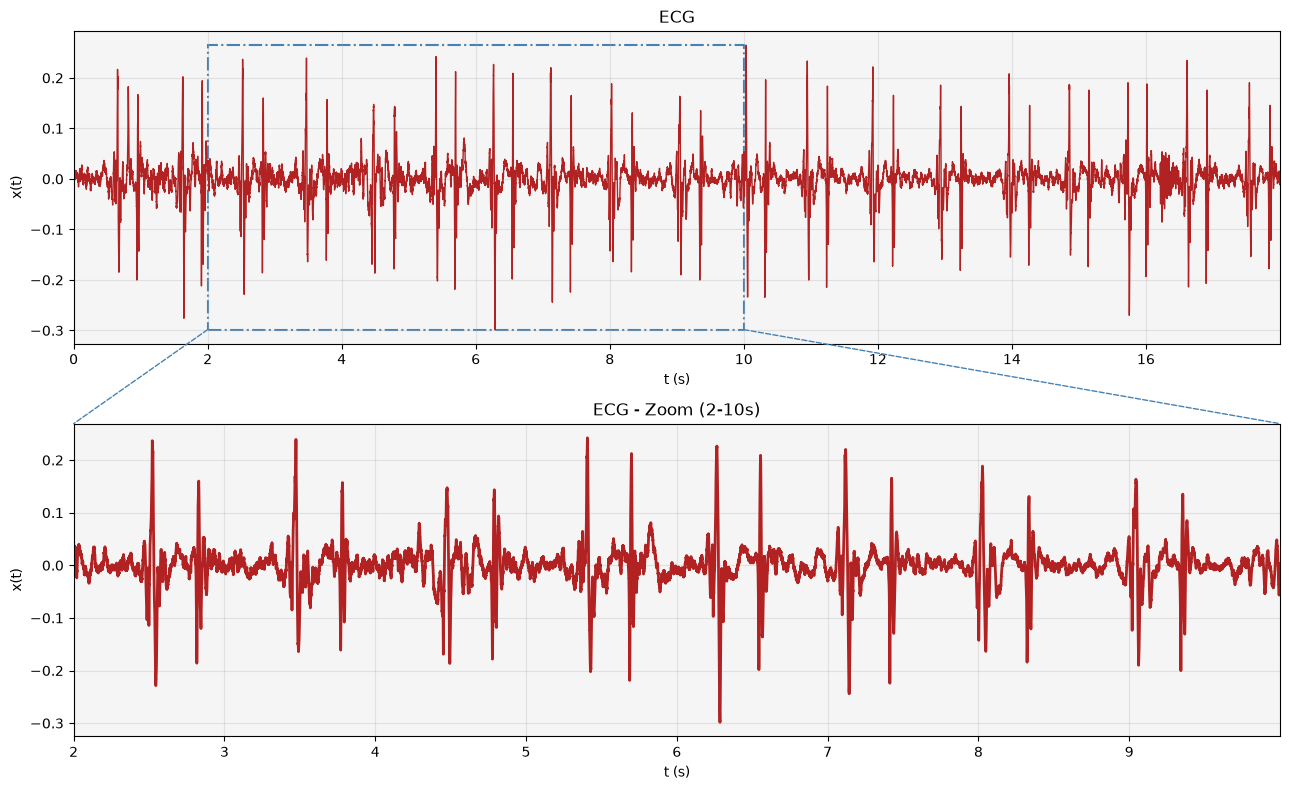

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, ConnectionPatch

t = np.arange(len(ecg)) / fs
window = slice(0, int(fs * 18))
window_zoom = slice(int(fs * 2), int(fs * 10))  # subset de 8s

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), facecolor='white')

# grafico completo
ax1.set_facecolor('whitesmoke')
ax1.plot(t[window], pcg[window], linewidth=1, color="firebrick")
ax1.set_xlim(t[window].min(), t[window].max())
ax1.grid(True, alpha=0.3)
ax1.set_title('ECG')
ax1.set_xlabel('t (s)')
ax1.set_ylabel("x(t)")

# rectángulo para ver el zoom in
t_zoom_start = t[window_zoom].min()
t_zoom_end = t[window_zoom].max()
y_min, y_max = pcg[window].min(), pcg[window].max()
rect = Rectangle(
    (t_zoom_start, y_min), t_zoom_end - t_zoom_start, y_max - y_min,
    linewidth=1.5, edgecolor='steelblue', facecolor='none', linestyle='-.'
)
ax1.add_patch(rect)

# grafico zoom
ax2.set_facecolor('whitesmoke')
ax2.plot(t[window_zoom], pcg[window_zoom], linewidth=2, color="firebrick")
ax2.set_xlim(t[window_zoom].min(), t[window_zoom].max())
ax2.grid(True, alpha=0.3)
ax2.set_title('ECG - Zoom (2-10s)')
ax2.set_xlabel('t (s)')
ax2.set_ylabel("x(t)")
y_zoom_min, y_zoom_max = pcg[window_zoom].min(), pcg[window_zoom].max()

# conectores
con1 = ConnectionPatch(
    xyA=(t_zoom_start, y_min), coordsA=ax1.transData,
    xyB=(0, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)

con2 = ConnectionPatch(
    xyA=(t_zoom_end, y_min), coordsA=ax1.transData,
    xyB=(1, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)
fig.add_artist(con1)
fig.add_artist(con2)

plt.tight_layout()
# plt.show()

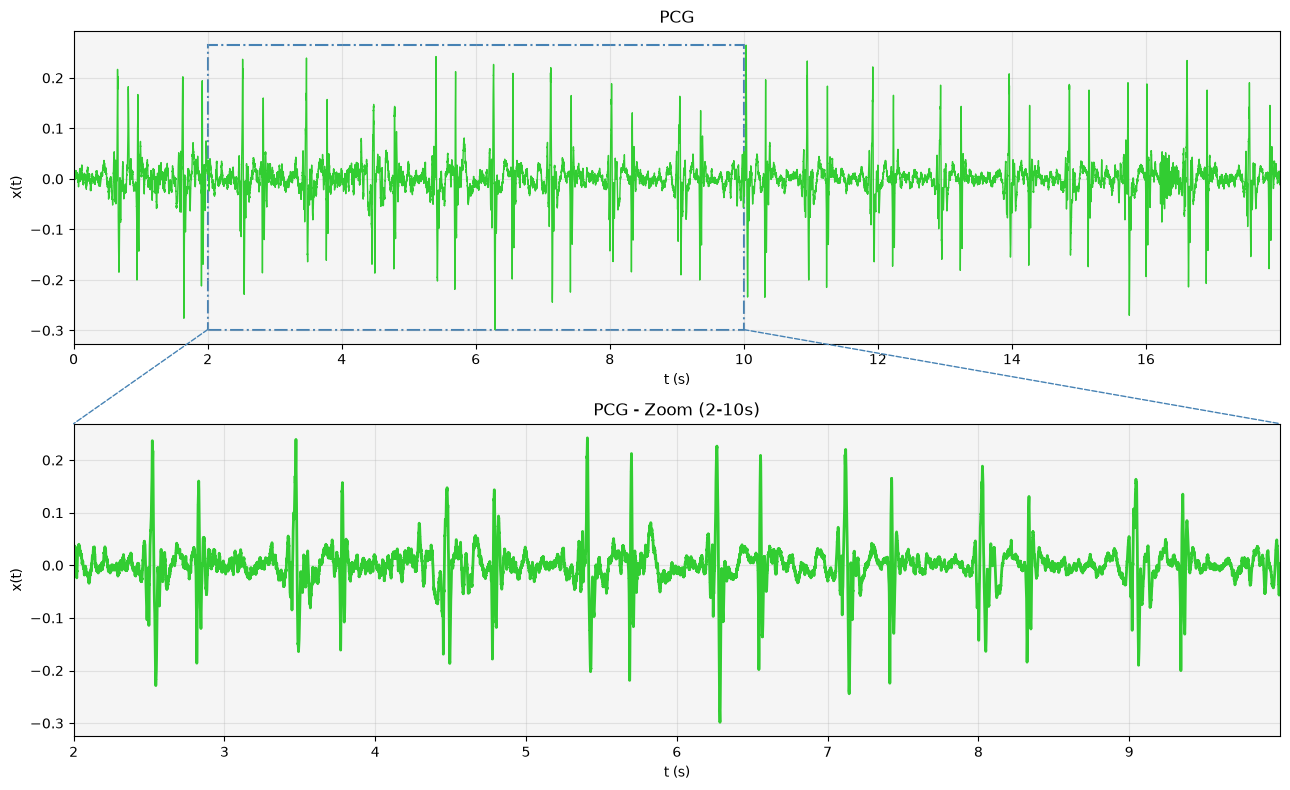

In [6]:
# @title
from matplotlib.patches import Rectangle, ConnectionPatch

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), facecolor='white')

# grafico completo
ax1.set_facecolor('whitesmoke')
ax1.plot(t[window], pcg[window], linewidth=1, color="limegreen")
ax1.set_xlim(t[window].min(), t[window].max())
ax1.grid(True, alpha=0.3)
ax1.set_title('PCG')
ax1.set_xlabel('t (s)')
ax1.set_ylabel("x(t)")

# rectángulo para ver el zoom in
t_zoom_start = t[window_zoom].min()
t_zoom_end = t[window_zoom].max()
y_min, y_max = pcg[window].min(), pcg[window].max()
rect = Rectangle(
    (t_zoom_start, y_min), t_zoom_end - t_zoom_start, y_max - y_min,
    linewidth=1.5, edgecolor='steelblue', facecolor='none', linestyle='-.'
)
ax1.add_patch(rect)

# grafico zoom
ax2.set_facecolor('whitesmoke')
ax2.plot(t[window_zoom], pcg[window_zoom], linewidth=2, color="limegreen")
ax2.set_xlim(t[window_zoom].min(), t[window_zoom].max())
ax2.grid(True, alpha=0.3)
ax2.set_title('PCG - Zoom (2-10s)')
ax2.set_xlabel('t (s)')
ax2.set_ylabel("x(t)")
y_zoom_min, y_zoom_max = pcg[window_zoom].min(), pcg[window_zoom].max()

# conectores
con1 = ConnectionPatch(
    xyA=(t_zoom_start, y_min), coordsA=ax1.transData,
    xyB=(0, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)

con2 = ConnectionPatch(
    xyA=(t_zoom_end, y_min), coordsA=ax1.transData,
    xyB=(1, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)
fig.add_artist(con1)
fig.add_artist(con2)

plt.tight_layout()
# plt.show()

Luego se puede muestrear las señales de PCG y ECG, observando que dado que el período de muestreo de las señales es: $\frac{1}{fs}=0.000125s$, el período elegido de muestreo debe ser igual o superior al mismo.
Se elige $T=0.5$.

A continuación se grafican las señales discretas obtenidas, recortando lo obtenido a $2-4s$ para simplificar la visualización. No se explicita el método de muestreo ideal via conversor A/D puesto a que ya fue detallado en el trabajo anterior.

In [7]:
def hacer_x_c_desde_array(t_data, x_data):
    def x_c(t_eval):
        return np.interp(t_eval, t_data, x_data)
    return x_c

def plot_señal_muestreada(x_c, t, T, titulo_senal=r'$x_c(t)$', figsize=(8, 4),color='limegreen'):
    step = t[1] - t[0]
    N = int(round(T / step))

    t_n = t[::N]
    n = np.arange(len(t_n))
    xc_cont = x_c(t)
    xc_en_tn = xc_cont[::N]

    fig, ax = plt.subplots(1, 1, figsize=figsize)

    markerline, stemlines, baseline = ax.stem(n, xc_en_tn, basefmt=" ")
    plt.setp(markerline, color=color)
    plt.setp(stemlines, color=color)
    ax.set_title(titulo_senal)
    ax.set_xlabel('n')
    ax.grid(True)

    plt.tight_layout()
    return fig, ax, (n, t_n, xc_en_tn)

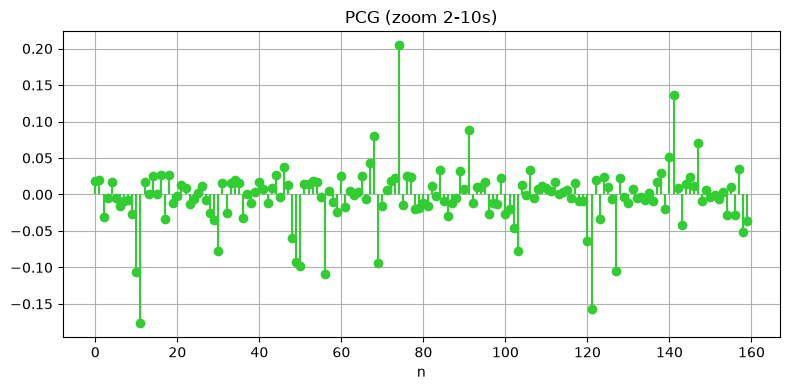

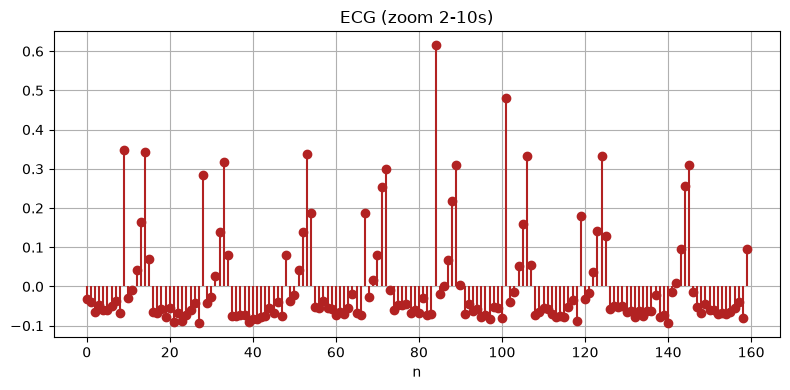

In [8]:
fs = 8000
t = np.arange(len(pcg)) / fs

window = slice(int(fs*2), int(fs*10))
t_win = t[window]
pcg_win = pcg[window]

x_c_pcg_win = hacer_x_c_desde_array(t_win, pcg_win)
fig, axs, (n, t_n, xn) = plot_señal_muestreada(x_c_pcg_win, t_win, T=0.05, titulo_senal='PCG (zoom 2-10s)',figsize=(8,4),color='limegreen')

ecg_win = ecg[window]
x_c_ecg_win = hacer_x_c_desde_array(t_win, ecg_win)
fig, axs, (n, t_n, xn) = plot_señal_muestreada(x_c_ecg_win, t_win, T=0.05, titulo_senal='ECG (zoom 2-10s)',figsize=(8,4),color='firebrick')


#### Transformada de Fourier

A partir de las señales discretas obtenidas, puede aplicarse la transformada de Fourier de tiempo discreto para obtener la información de la señal en términos de frecuencia.
Para obtener la DTFT de una señal, debe hacerse:
$$
  \hat{X}=\mathcal{F}_d\{x[n]\}(f)=\sum_{n=-\infty}^{+\infty}x[n]e^{-i2\pi f_d n}
$$
Esta expresión presenta distintos problemas de implementación, dado que _no_ es computable. En primer lugar, la sumatoria exige una cantidad infinita de muestras, con lo cual no es compatible con señales reales (sin descripción analítica). Por el otro lado, la DTFT trabaja con frecuencia continua, lo cual implica un problema de implementación, ya que no pueden almacenarse todas las frecuencias.

Luego puede proponerse la DFT como solución a estos problemas. La idea es "muestrear" la DTFT a partir de una cantidad N de muestras:
$$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-i2\pi f_k n}\qquad f_k=\frac{k}{N}, k\in \{0,...,N-1\}
$$
De esta manera, se pasa a trabajar con secuencias finitas y espectro en variable discreta, aproximando así la transformada de Fourier de tiempo discreto.
En particular, puede utilizarse el algoritmo FFT para calcular DFT.

Luego puede aplicarse este algoritmo para computar la transformada de las señalkes de PCG y ECG. Cabe aclarar que para esto es necesario que las señales sean de _largo finito_, lo cual estas señales cumplen dado que son señales reales no definidas fuera del tiempo observado.
Para acortar el tiempo de ejecución, se toma la ventana utilizada previamente de $8s$ para computar la DFT de las señales de PCG y ECG.

In [9]:
## referencia de: https://agustinsolano.github.io/SyS_scriptsbook/md_scripts/Computo_TFourier_FFT_senial_real.html

import numpy as np
import matplotlib.pyplot as plt

def dtft_muestreada(x, fs, nfft=None):
    x = np.asarray(x)
    if nfft is None:
        nfft = len(x) # default es N, cantidad de muestras

    X = np.fft.fftshift(np.fft.fft(x, n=nfft))
    k = np.arange(-(nfft // 2), nfft - nfft // 2)
    f = k * fs / nfft
    return f, X

def plot_dtft(x, fs, nfft=None, titulo='PCG', umbral_fase=1e-3, fmax=500, color='C0'):
    f, X = dtft_muestreada(x, fs, nfft)
    sel = np.abs(f) <= fmax
    f_p, X_p = f[sel], X[sel]

    mag = np.abs(X_p)
    fase = np.angle(X_p)
    fase[mag < umbral_fase * mag.max()] = 0 # en teoría fuera del rango de info del módulo la fase debiiera ser ruido

    fig, axs = plt.subplots(2, 1, figsize=(12, 8))

    ml, sl, _ = axs[0].stem(f_p, mag, basefmt=" ")
    plt.setp(ml, color=color, markersize=3); plt.setp(sl, color=color, linewidth=0.8)
    axs[0].set_title(rf'{titulo} - $|X(f_k)|$')
    axs[0].set_ylabel('Magnitud [u.a.]'); axs[0].grid(True)
    axs[0].set_xlabel('Frecuencia [Hz]')

    ml, sl, _ = axs[1].stem(f_p, fase, basefmt=" ")
    plt.setp(ml, color=color, markersize=3); plt.setp(sl, color=color, linewidth=0.8)
    axs[1].set_title(rf'{titulo} - $\angle X(f_k)$')
    axs[1].set_ylabel('Fase [rad]')
    axs[1].set_xlabel('Frecuencia [Hz]')
    axs[1].grid(True)

    axs[0].set_xlim(-fmax, fmax)
    plt.tight_layout()
    return fig, axs, (f, X)      # devuelve el espectro completo, no solo el recortado

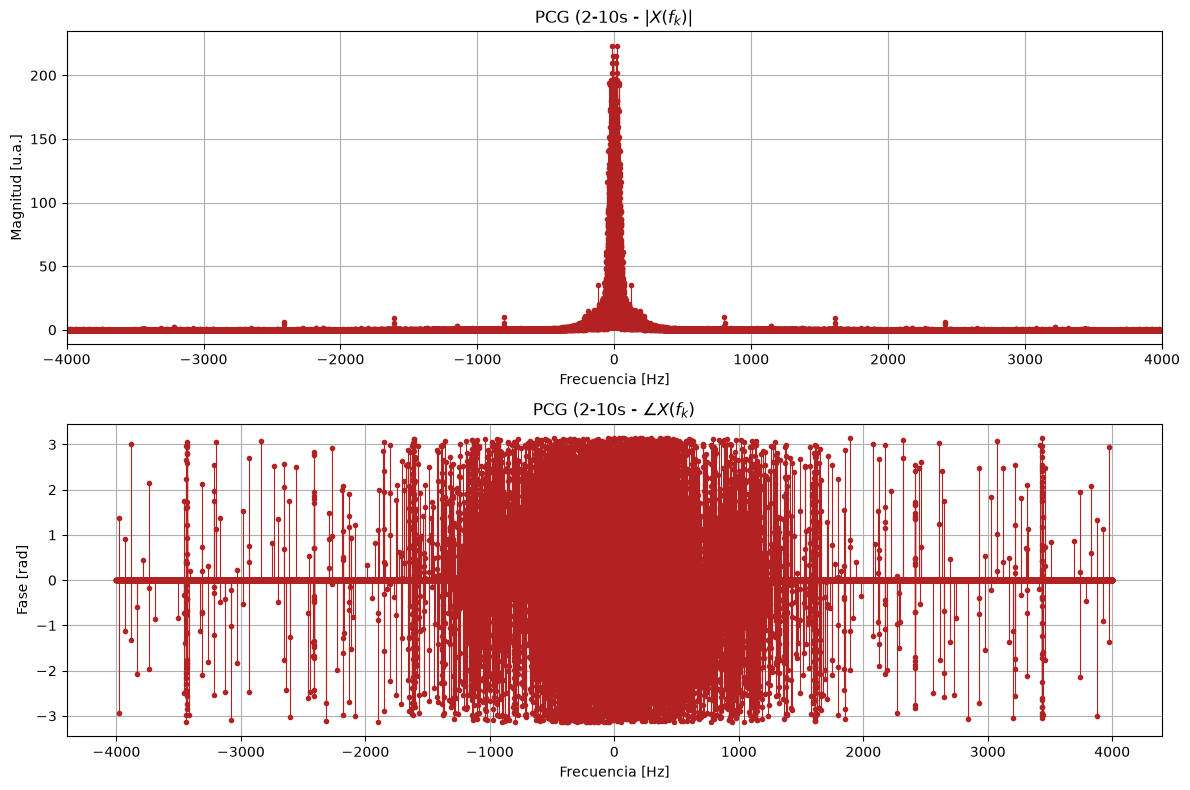

In [10]:
fig, axs, (f, X) = plot_dtft(pcg_win, fs, titulo='PCG (2-10s', fmax=fs/2,color='firebrick')

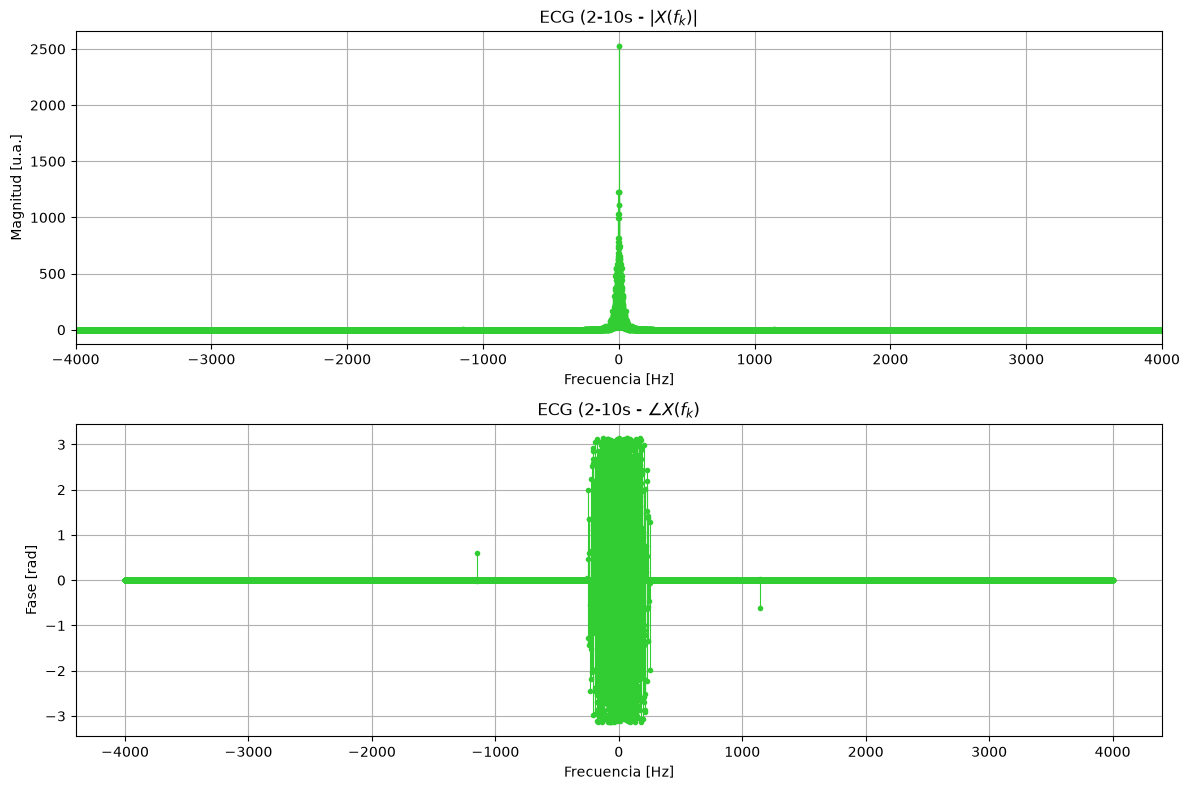

In [11]:
fig, axs, (f, X) = plot_dtft(ecg_win, fs, titulo='ECG (2-10s', fmax=fs/2,color='limegreen')

#### Análisis de ECG y PCG

El ECG (o electrocardiograma) es un estudio que mide la actividad eléctrica del corazón. Dentro del mismo pueden identificarse distintas ondas, correspondientes a los eventos que se repiten en cada latido a nivel eléctrico. En particular:

- **P**: resultado de la activación eléctrica de las aurículas (cavidades superiores del corazón). Es una onda pequeña y redondeada, de duración $\leq 120 \mathrm{ms}$ y amplitud $\leq 0.25\mathrm{mV}$. Su contenido en frecuencia se concentra entre 5 y 30 Hz como máximo.
- **Q, R, S**: producto de la activación de los ventrículos (cavidades infriores). La R es el pico más alto y angosto de la señal. Dura unos 70-110 ms y concentra su energía entre 8 y 50 Hz, centrado en 10 Hz.
- **T**: repolarización de los ventrículos. Es una onda ancha y lenta, con contenido principalmente entre 0 y 10 Hz.
- **RR**: no es una onda sino el intervalo entre dos picos R consecutivos, es decir, la duración de un latido. A partir de él se obtienen la frecuencia cardíaca y la variabilidad del ritmo. Corresponde a una frecuencia de aproximadamente 1 Hz (dependiendo el ritmo cardíaco del paciente).

El PCG (fonocardiograma), por el otro lado, registra los sonidos cardíacos mediante un micrófono colocado en la pared torácica del paciente. Pueden identificarse distintos eventos a partir de los sonidos detectados:

- **S1**: primer ruido cardíaco, producido por el cierre de las válvulas mitral y tricúspide al inicio de la sístole. Ocurre inmediatamente después del pico R del ECG. Su contenido en frecuencia se extiende de unos 10 a 150 Hz, con máxima energía alrededor de 25-45 Hz.
- **S2**: segundo ruido cardíaco, producido por el cierre de las válvulas aórtica y pulmonar al final de la sístole, cerca del final de la onda T. Es algo más agudo que S1: abarca de unos 10 a 200 Hz, con máxima energía alrededor de 55-75 Hz.
- **S3/S4**: sonidos débiles de la diástole, de muy baja frecuencia (aproximadamente 15-70 Hz).
- **Soplos**: producidos por flujo turbulento, de mayor frecuencia y carácter ruidoso, entre unos 25 y 400 Hz, pudiendo extenderse hasta unos 600 Hz con menor energía. Representan anomalías cardíacas.

Los intervalos entre S1 y S2 representan la _sístole_ y entre S2 y el siguiente S1 la _diástole_. La presencia de componentes de alta frecuencia en ellos es un indicio de soplos o _clics_.

A partir de la DFT de las señales, podemos observar que el contenido de las mismas se concentra alrededor de las bajas frecuencias. Esto puede verse más claramente al graficar alrededor de este rango. Esto es consistente con el origen de las señales: la información del ECG se encuentra dentro de la franja de $150Hz$ como máximo, y el PCG contiene información hasta $400Hz$ si se detectan anomalías como soplos.


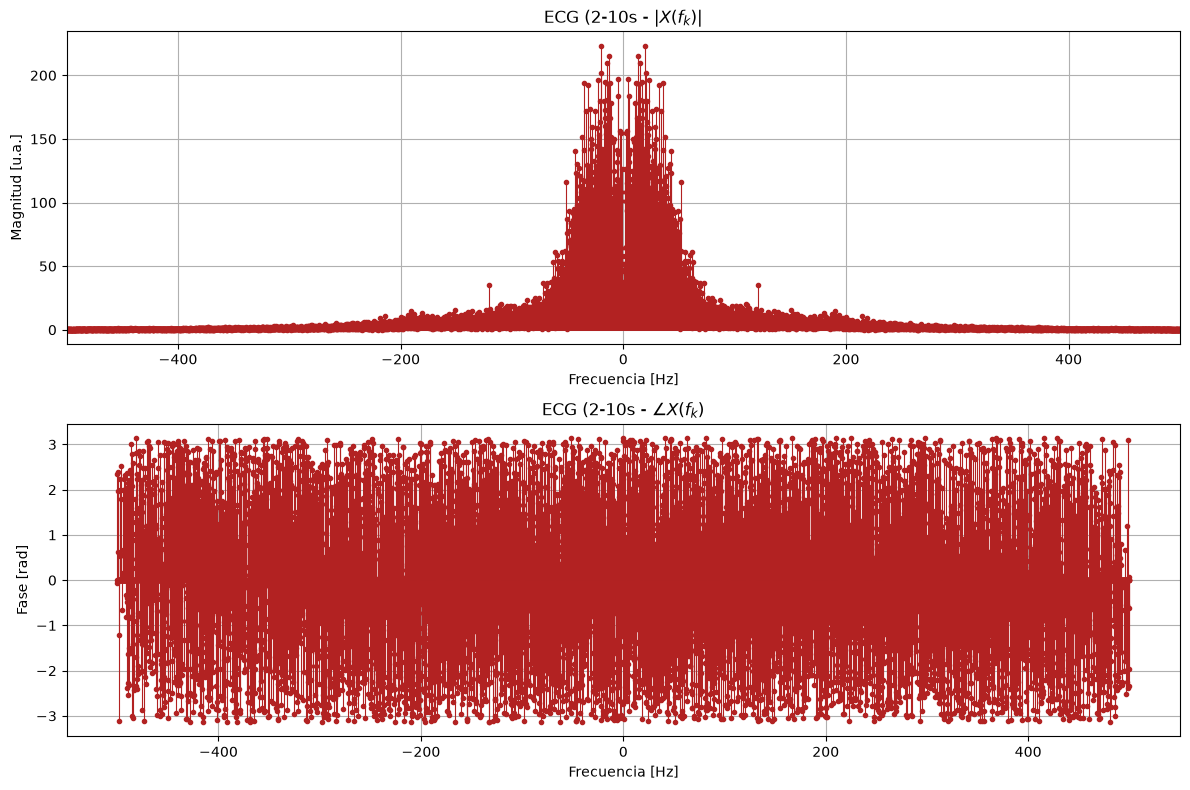

In [12]:
fig, axs, (f, X) = plot_dtft(pcg_win, fs, titulo='ECG (2-10s', fmax=500,color='firebrick')

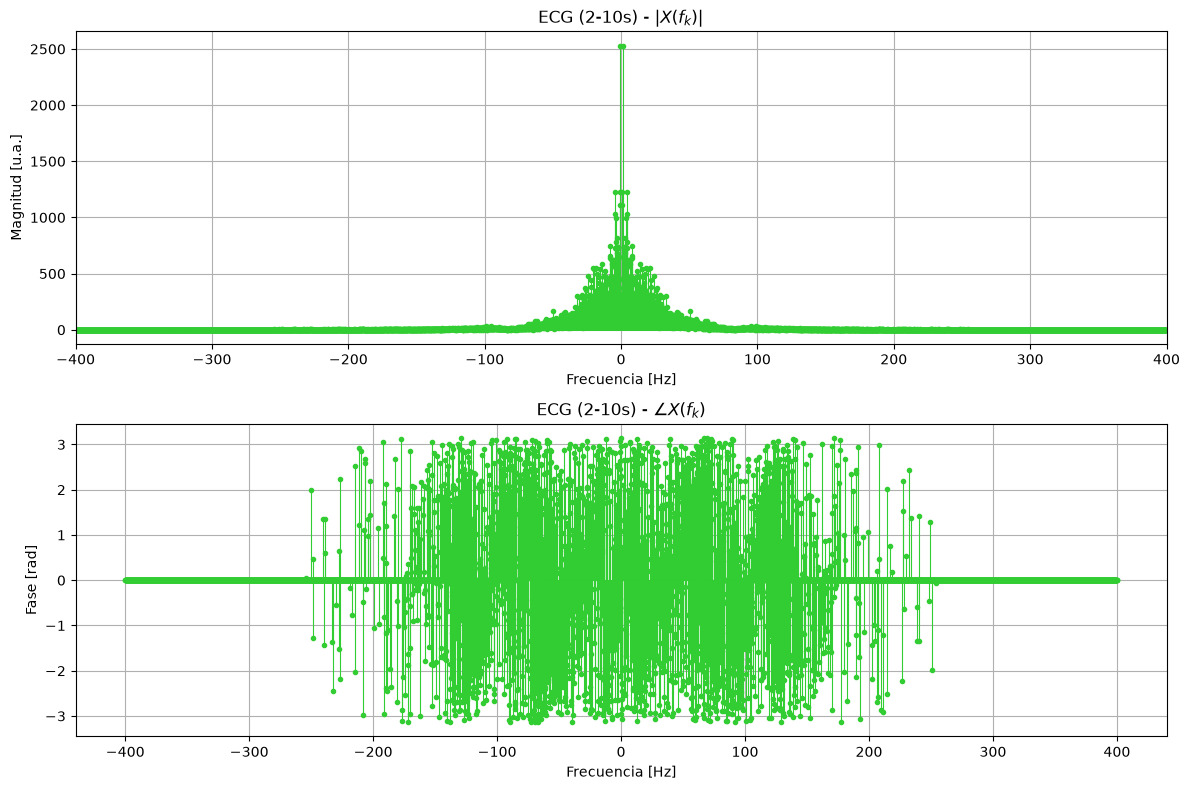

In [13]:
fig, axs, (f, X) = plot_dtft(ecg_win, fs, titulo='ECG (2-10s)', fmax=150,color='limegreen')

Luego para analizar la información de las señales, pueden emplearse filtros para rechazar el ruido introducido durante las mediciones (pasa-bajos con frecuencia de corte en $\sim 400Hz$ para PCG, y en $\sim 150Hz$ para ECG), y luego procesarlas (con otros filtros, o incluso utilizando una red neuronal a modo de clasificador), para identificar las ondas que componen estas señales, aislarlas, y detectar anomalías.

En particular, para detectar la onda QRS puede utilizarse un filtro pasa-banda que rechaza frecuencias fuera del rango $5-15Hz$, dado que es en esta banda donde se concentra gran parte de su energía (Pan y Tompkins, 1985 ([fuente](https://www.robots.ox.ac.uk/~gari/teaching/cdt/A3/readings/ECG/Pan+Tompkins.pdf))).

Sin embargo, como varias de las ondas comparten parte de sus bandas de frecuencia, no siempre es posible aislarlas únicamente utilizando filtros. En el ECG, la onda P ($\sim 5\text{-}30\,\mathrm{Hz}$) y el complejo QRS ($\sim 8\text{-}50\,\mathrm{Hz}$) se superponen en frecuencia, y la onda T ($\sim 0\text{-}10\,\mathrm{Hz}$) se superpone con la P. En el PCG, S1 y S2 ocupan bandas muy parecidas, y los soplos, de mayor frecuencia, aparecen en los intervalos entre ambos sonidos, de modo que la frecuencia por sí sola no permite distinguir un sonido de otro.
Por este motivo, el filtrado se debe combinar con información temporal: pueden detectarse los picos R y, tomando ventanas de tiempo respecto de ellos, aislar cada onda del ECG y promediar los latidos para reducir el ruido. De la misma forma, en el PCG se pueden ubicar S1 y S2 a partir del pico R y analizar por separado la sístole y la diástole.

## Implementación de Procesamientos Básicos

A continuación se implementan distintos procesamientos básicos de señales. Cada procesamiento se modela como un sistema, observando el resultado al poner en la entrada las señales de ECG y PCG, analizando la salida en el dominio temporal y frecuencial.
Cabe aclarar que se utilizan gráficos de tipo continuo y discreto de manera indistinta, según lo que resulte más conveniente para la visualización.

#### Submuestreo y sobremuestreo


El submuestreo de una señal (es decir, su compresión) puede modelarse como:

$$y[n] = x[nM], \qquad M\in \mathbb{N}$$

De esta manera, se conservan únicamente las muestras de $x$ tales que $n \bmod M = 0$ y se descartan las demás. La frecuencia de muestreo pasa de $f_s$ a $f_s' = f_s/M$, y por lo tanto el espectro de $y$ queda definido solo en la banda $[-f_s'/2,\ f_s'/2)$, que es $M$ veces más angosta que la de $x$. En términos de la frecuencia $f$ en Hz, el espectro de $y$ es la superposición de $M$ réplicas del de $x$ desplazadas múltiplos de $f_s'$:

$$Y(f) = \frac{1}{M}\sum_{k=0}^{M-1} X\!\left(f - k f_s'\right)$$

Si $x$ tiene componentes por encima de $f_s'/2$, las réplicas se solapan y aparece aliasing. Por eso, antes de descartar muestras se debe aplicar un filtro pasa-bajos con corte en $f_s'/2$. En ese caso las componentes por encima de $f_s'/2$ simplemente se pierden.

En particular, para el ECG y PCG: el PCG tiene información hasta $\sim 400\,\mathrm{Hz}$, por lo que para no perderla se necesita $f_s' \geq 800\,\mathrm{Hz}$ (es decir, $M \leq 10$).
El ECG, por su parte, tiene información hasta $\sim 150\,\mathrm{Hz}$, por lo que alcanza con $f_s' \geq 300\,\mathrm{Hz}$ (es decir, $M \leq 26$). Para hacer evidente la reducción de la cantidad de muestras y la pérdida de información, se utilizan valores de $M$ deliberadamente mayores: $M=40$ para el PCG ($f_s'=200\,\mathrm{Hz}$) y $M=80$ para el ECG ($f_s'=100\,\mathrm{Hz}$).
Con estos valores, la banda representable es de solo $\pm 100\,\mathrm{Hz}$ y $\pm 50\,\mathrm{Hz}$ respectivamente, y el resto del contenido de la señal queda fuera de ella.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import decimate

def submuestreo(x, M, antialias=True):
# utilizamos una función que ya aplica el filtro antialiasing
    if antialias:
        return decimate(x, M, ftype='fir', zero_phase=True)
    return x[::M]


M_pcg = 40
pcg_sub = submuestreo(pcg, M_pcg)
fs_pcg = fs / M_pcg
t_pcg_sub = np.arange(len(pcg_sub)) / fs_pcg

M_ecg = 80
ecg_sub = submuestreo(ecg, M_ecg)
ecg_sub_naive = submuestreo(ecg, M_ecg, antialias=False)
fs_ecg = fs / M_ecg
t_ecg_sub = np.arange(len(ecg_sub)) / fs_ecg

print(f"PCG: {len(pcg)} -> {len(pcg_sub)} muestras, fs' = {fs_pcg:.0f} Hz")
print(f"ECG: {len(ecg)} -> {len(ecg_sub)} muestras, fs' = {fs_ecg:.0f} Hz")

PCG: 14400000 -> 360000 muestras, fs' = 200 Hz
ECG: 14400000 -> 180000 muestras, fs' = 100 Hz


(<Figure size 1200x700 with 2 Axes>,
 array([<Axes: title={'center': 'ECG: $x[n]$ ($f_s=8000$ Hz'}, xlabel='n'>,
        <Axes: title={'center': "ECG: $y[n]=x[nM]$, $M=16$ ($f_s'=500$ Hz"}, xlabel='n'>],
       dtype=object))

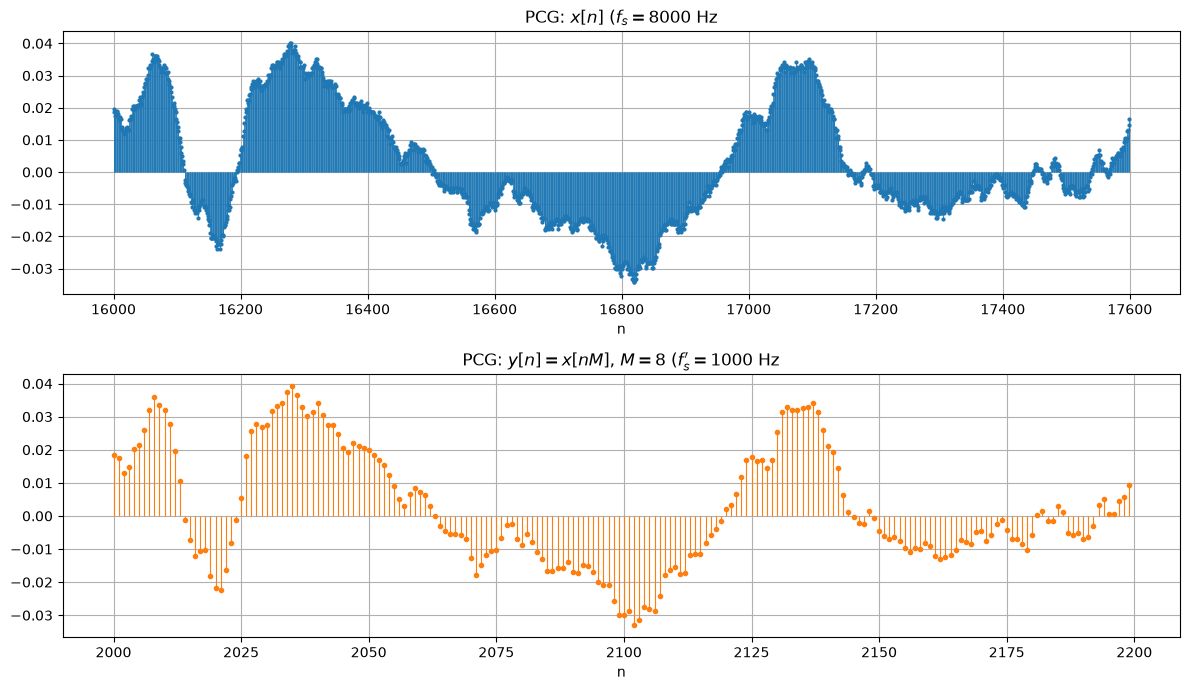

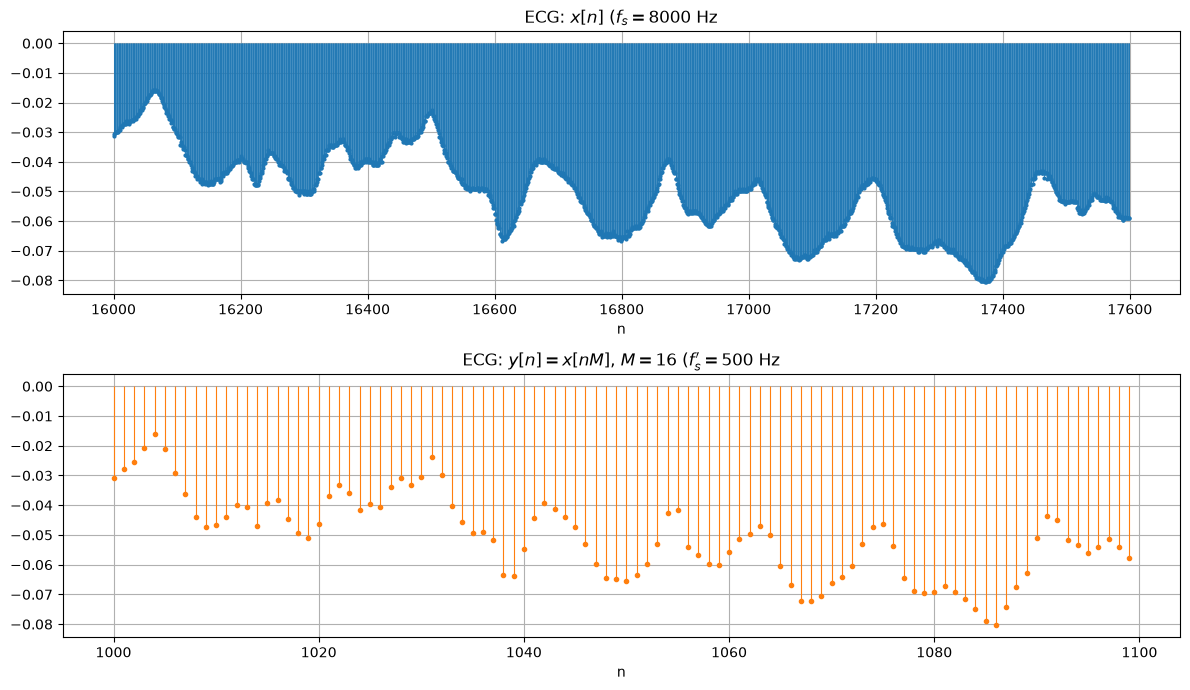

In [27]:
def comparar_submuestreo(x, fs, M, titulo, t_ini=2, t_fin=2.2):
    x_sub = submuestreo(x, M)

    n_ini, n_fin = int(t_ini * fs), int(t_fin * fs)
    n = np.arange(n_ini, n_fin)
    m = np.arange(n_ini // M, n_fin // M)

    fig, axs = plt.subplots(2, 1, figsize=(12, 7))

    # x[n]
    ml, sl, _ = axs[0].stem(n, x[n_ini:n_fin], basefmt=" ")
    plt.setp(ml, color='C0', markersize=2); plt.setp(sl, color='C0', linewidth=0.6)
    axs[0].set_title(rf"{titulo}: $x[n]$ ($f_s={fs}$ Hz")
    axs[0].set_xlabel('n'); axs[0].grid(True)

    # y[n] = x[nM]
    ml, sl, _ = axs[1].stem(m, x_sub[m[0]:m[-1] + 1], basefmt=" ")
    plt.setp(ml, color='C1', markersize=3); plt.setp(sl, color='C1', linewidth=0.8)
    axs[1].set_title(rf"{titulo}: $y[n]=x[nM]$, $M={M}$ ($f_s'={fs/M:.0f}$ Hz")
    axs[1].set_xlabel('n'); axs[1].grid(True)

    plt.tight_layout()
    return fig, axs

comparar_submuestreo(pcg, fs, 8,  'PCG')
comparar_submuestreo(ecg, fs, 16, 'ECG')

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'ECG: submuestreo con $M=80$'}, xlabel='Frecuencia [Hz]', ylabel='Magnitud normalizada [u.a.]'>)

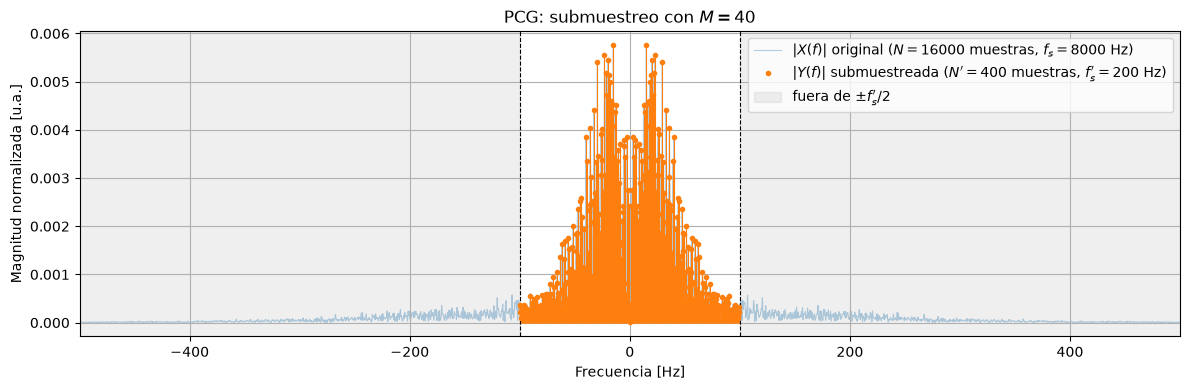

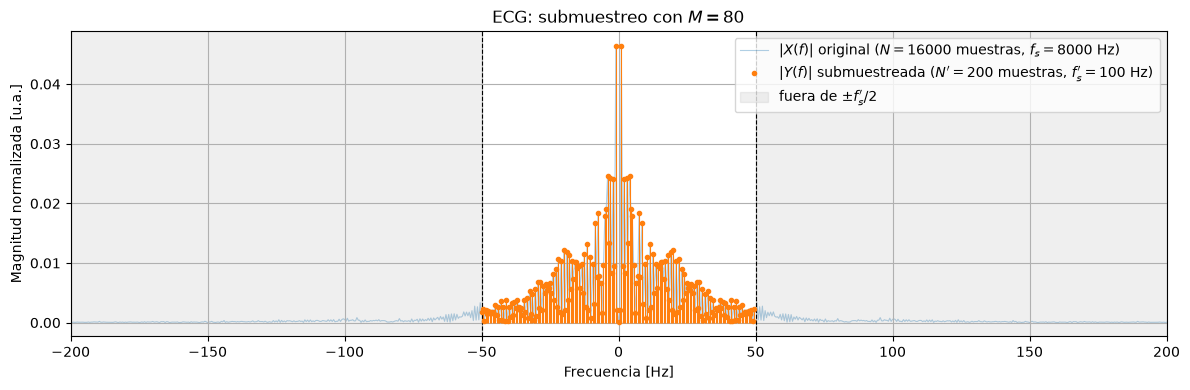

In [28]:
def graficar_submuestreo_frec(x, fs, M, titulo, t_ini=2, t_fin=4, fmax=500,
                              antialias=True, color_orig='C0', color_sub='C1'):
    xv = np.asarray(x[int(t_ini * fs):int(t_fin * fs)], dtype=float)
    xv = xv - xv.mean()
    y = submuestreo(xv, M, antialias)                    # y[n] = x[nM]
    fs_sub = fs / M

    f_x, X = dtft_muestreada(xv, fs)
    f_y, Y = dtft_muestreada(y, fs_sub)
    Xm = np.abs(X) / len(xv)
    Ym = np.abs(Y) / len(y)                              # para que sean comparables

    sel_x = np.abs(f_x) <= fmax
    sel_y = np.abs(f_y) <= fmax

    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(f_x[sel_x], Xm[sel_x], color=color_orig, alpha=0.35, linewidth=0.8,
            label=rf'$|X(f)|$ original ($N={len(xv)}$ muestras)', zorder=1)

    ml, sl, _ = ax.stem(f_y[sel_y], Ym[sel_y], basefmt=" ")
    plt.setp(ml, color=color_sub, markersize=3, zorder=3)
    plt.setp(sl, color=color_sub, linewidth=0.8, zorder=2)
    ml.set_label(rf"$|Y(f)|$ submuestreada ($N'={len(y)}$ muestras")

    # banda que y no puede representar
    ax.axvline(-fs_sub / 2, color='k', linestyle='--', linewidth=0.8)
    ax.axvline( fs_sub / 2, color='k', linestyle='--', linewidth=0.8)
    ax.axvspan(-fmax, -fs_sub / 2, color='gray', alpha=0.12)
    ax.axvspan( fs_sub / 2,  fmax, color='gray', alpha=0.12, label=r'fuera de $\pm f_s^{\prime}/2$')

    ax.set_xlim(-fmax, fmax)
    ax.set_title(f"{titulo}: submuestreo con $M={M}$")
    ax.set_xlabel('Frecuencia [Hz]'); ax.set_ylabel('Magnitud normalizada')
    ax.grid(True); ax.legend(loc='upper right')
    plt.tight_layout()
    return fig, ax

graficar_submuestreo_frec(pcg, fs, M=40, titulo='PCG', fmax=500)
graficar_submuestreo_frec(ecg, fs, M=80, titulo='ECG', fmax=200)

> Aclaración: se normaliza por $N$ y $N'$. Sin esto, $|Y|$ sale unas $M$ veces más chico que $|X|$ porque la suma tiene $M$ veces menos términos, y no se podrían comparar las alturas

El sobremuestreo de una señal (expansión) se modela en dos pasos. Primero se insertan $L-1$ ceros entre cada par de muestras (expansor):

$$y_e[n] = \begin{cases} x[n/L] & \text{si } n \bmod L = 0 \\ 0 & \text{en otro caso} \end{cases}, \qquad L\in \mathbb{N}$$

La frecuencia de muestreo pasa de $f_s$ a $f_s' = L f_s$. Este paso no agrega información, solo "estira" el eje temporal. En frecuencia, $Y_e(e^{j\omega}) = X(e^{j\omega L})$, es decir, el espectro de $x$, que ya era periódico con período $f_s$, queda ahora observado en una banda $L$ veces más ancha. Dentro de $[-f_s'/2,\ f_s'/2)$ aparecen entonces $L$ copias del espectro original centradas en los múltiplos de $f_s$: la banda base y $L-1$ imágenes:


$$Y_e(f) = X(f), \qquad X(f) = X(f - k f_s)$$

Además, como se agregaron ceros, el nivel medio de la señal baja un factor $L$.

El segundo paso es la interpolación lineal, que reemplaza cada cero por el valor sobre la recta que une las dos muestras originales vecinas. Para $n = kL + r$, con $0 \leq r < L$:


$$y[n] = x[k] + \frac{r}{L}\bigl(x[k+1] - x[k]\bigr)$$


En particular, para el ECG y PCG se sobremuestrea con $L=4$, llevando las señales de $f_s=8\,\mathrm{kHz}$ a $f_s'=32\,\mathrm{kHz}$

In [29]:
import numpy as np
import matplotlib.pyplot as plt

def sobremuestreo(x, L, interpolar=True):
    x = np.asarray(x, dtype=float)
    N = len(x)
    if interpolar:
        n = np.arange((N - 1) * L + 1)
        return np.interp(n / L, np.arange(N), x)
    y = np.zeros((N - 1) * L + 1)
    y[::L] = x
    return y

L = 4

(<Figure size 1200x700 with 2 Axes>,
 array([<Axes: title={'center': 'ECG: SIN interpolación'}, ylabel='Amplitud'>,
        <Axes: title={'center': 'ECG: CON interpolación lineal'}, xlabel='n', ylabel='Amplitud'>],
       dtype=object))

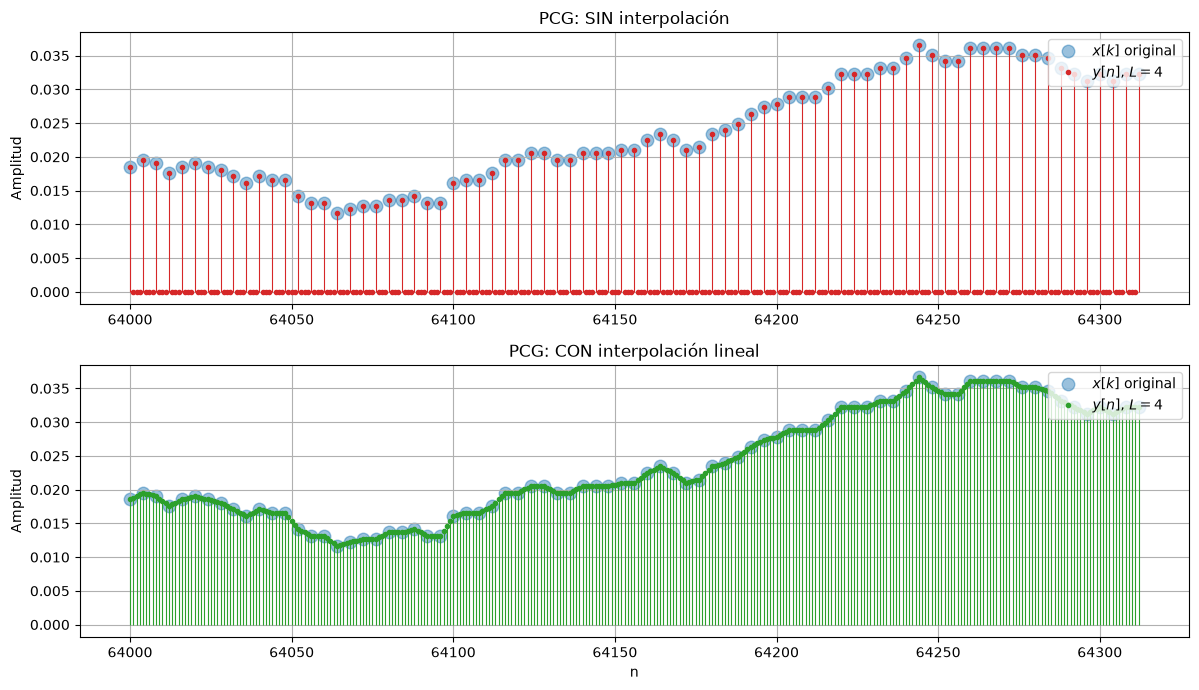

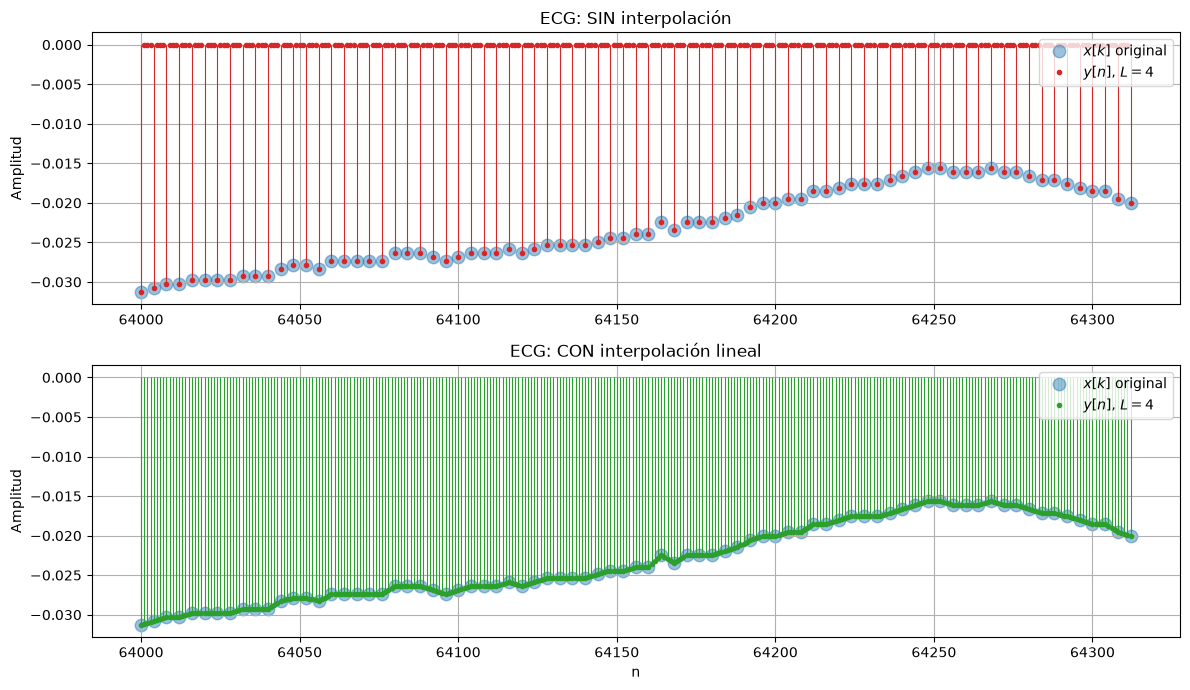

In [33]:
def comparar_sobremuestreo(x, fs, L, titulo, t_ini=2, t_fin=2.01):
    k_ini, k_fin = int(t_ini * fs), int(t_fin * fs)
    xv = np.asarray(x[k_ini:k_fin], dtype=float)

    y_sin = sobremuestreo(xv, L, interpolar=False)
    y_con = sobremuestreo(xv, L, interpolar=True)

    n = np.arange(len(y_sin)) + k_ini * L            # índice de y[n]
    k = np.arange(len(xv)) * L + k_ini * L           # posición de x[k] en el eje n (n = kL)

    fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True)

    for ax, y, color, sub in [(axs[0], y_sin, 'C3', 'SIN interpolación'),
                              (axs[1], y_con, 'C2', 'CON interpolación lineal')]:
        ax.plot(k, xv, 'o', color='C0', alpha=0.45, markersize=9,
                label=r'$x[k]$ original', zorder=1)

        ml, sl, _ = ax.stem(n, y, basefmt=" ")
        plt.setp(ml, color=color, markersize=3, zorder=3)
        plt.setp(sl, color=color, linewidth=0.8, zorder=2)
        ml.set_label(rf'$y[n]$, $L={L}$')

        ax.set_title(f"{titulo}: {sub}")
        ax.tick_params(labelbottom=True)
        ax.set_ylabel('Amplitud'); ax.grid(True); ax.legend(loc='upper right')

    axs[1].set_xlabel('n')
    plt.tight_layout()
    return fig, axs

comparar_sobremuestreo(pcg, fs, L, 'PCG', t_ini=2, t_fin=2.01)
comparar_sobremuestreo(ecg, fs, L, 'ECG', t_ini=2, t_fin=2.01)

Luego puede verse de mejor manera el efecto de la interpolación haciendo zoom en $2-2.001s$

(<Figure size 1200x700 with 2 Axes>,
 array([<Axes: title={'center': 'ECG: SIN interpolación'}, ylabel='Amplitud'>,
        <Axes: title={'center': 'ECG: CON interpolación lineal'}, xlabel='n', ylabel='Amplitud'>],
       dtype=object))

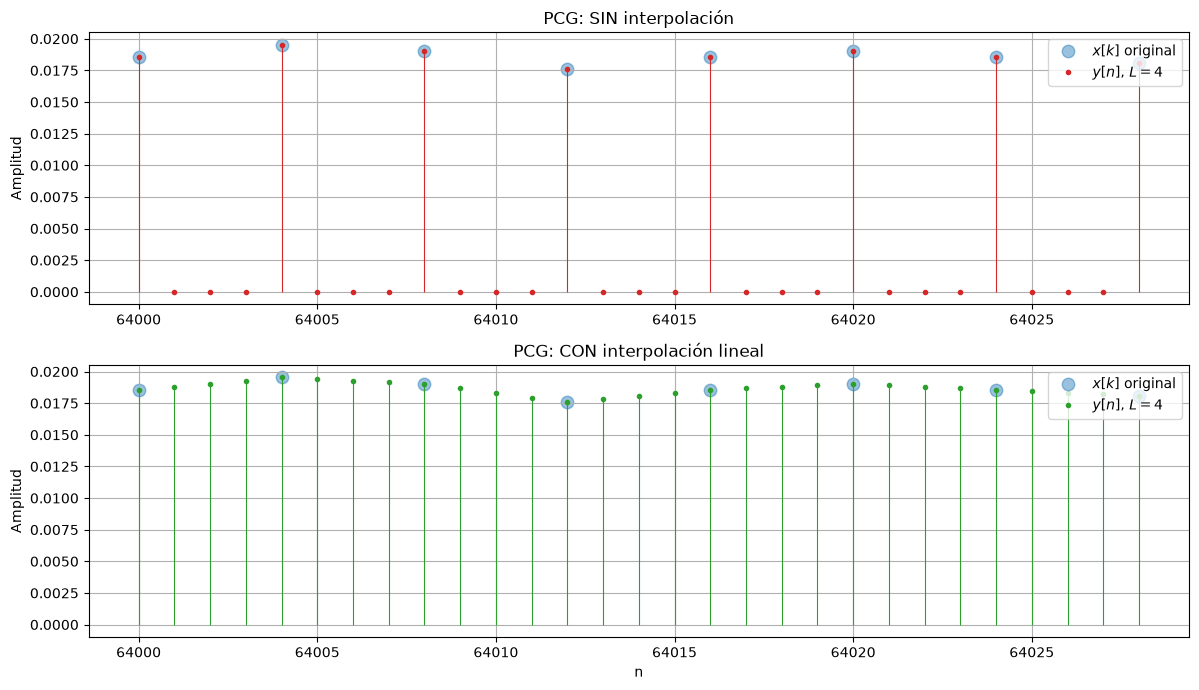

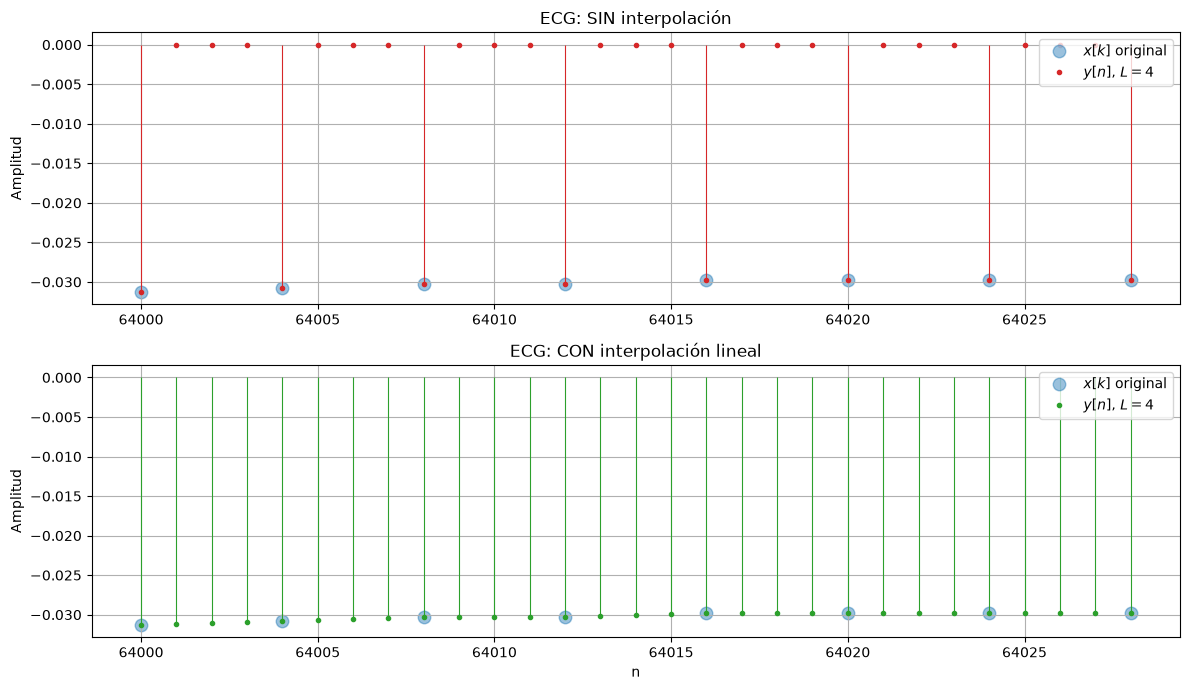

In [36]:
comparar_sobremuestreo(pcg, fs, L, 'PCG', t_ini=2, t_fin=2.001)
comparar_sobremuestreo(ecg, fs, L, 'ECG', t_ini=2, t_fin=2.001)

(<Figure size 1200x800 with 2 Axes>,
 array([<Axes: title={'center': 'ECG: SIN interpolación'}, ylabel='Magnitud normalizada [u.a.]'>,
        <Axes: title={'center': 'ECG: CON interpolación lineal'}, xlabel='Frecuencia [Hz]', ylabel='Magnitud normalizada [u.a.]'>],
       dtype=object))

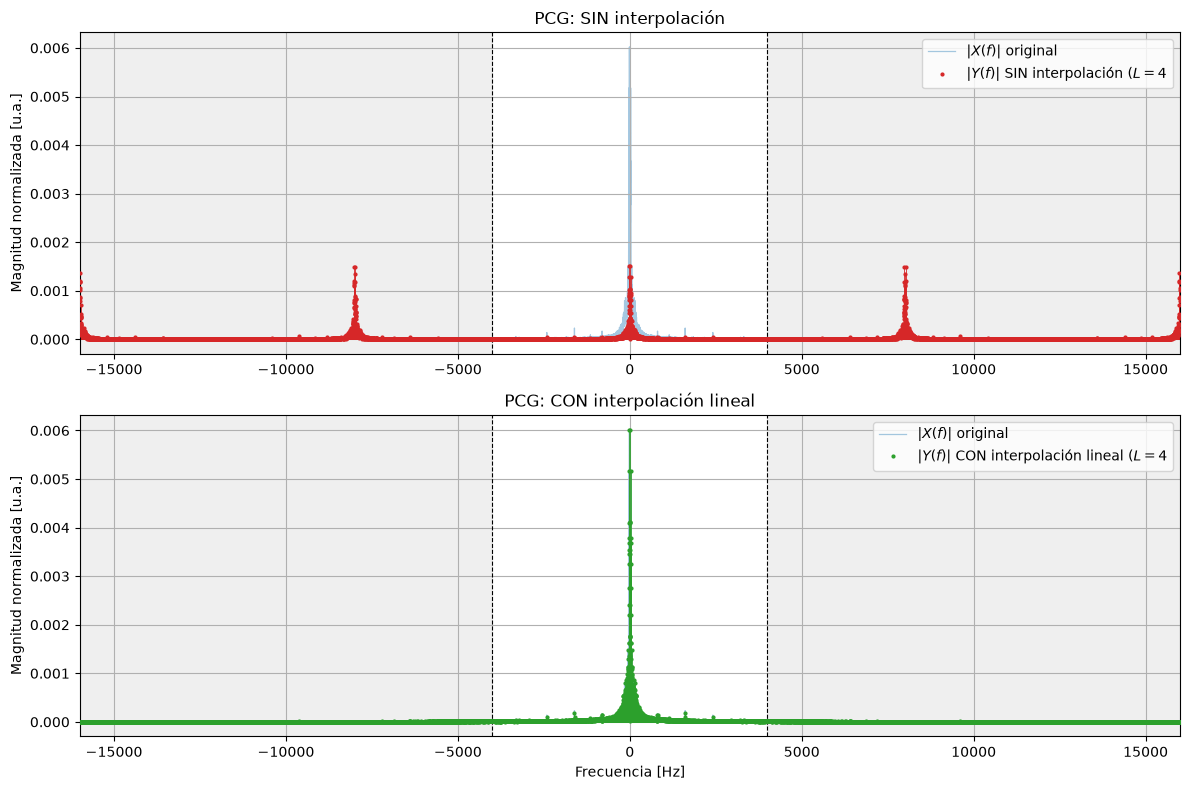

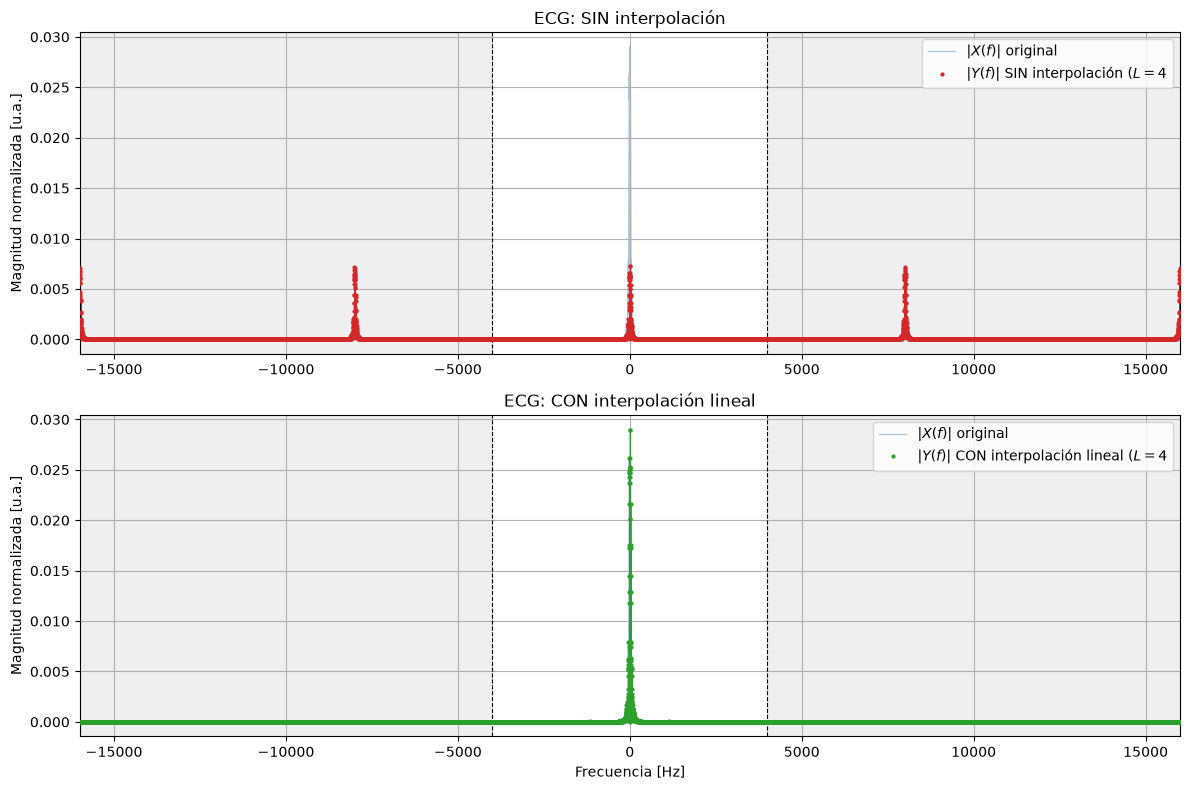

In [38]:
def graficar_imagenes(x, fs, L, titulo, t_ini=2, t_fin=2.5, color_orig='C0'):
    xv = np.asarray(x[int(t_ini * fs):int(t_fin * fs)], dtype=float)
    xv = xv - xv.mean()                              # saca el pico de DC
    fs_up = fs * L
    fmax = fs_up / 2

    y_sin = sobremuestreo(xv, L, interpolar=False)
    y_con = sobremuestreo(xv, L, interpolar=True)

    f_x, X = dtft_muestreada(xv, fs)
    Xm = np.abs(X) / len(xv)                         # normalizo por cantidad de muestras

    fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True, sharey=True)

    for ax, y, color, sub in [(axs[0], y_sin, 'C3', 'SIN interpolación'),
                              (axs[1], y_con, 'C2', 'CON interpolación lineal')]:
        f_y, Y = dtft_muestreada(y, fs_up)
        Ym = np.abs(Y) / len(y)

        # original por detrás
        ax.plot(f_x, Xm, color=color_orig, alpha=0.4, linewidth=0.9,
                label=rf'$|X(f)|$ original', zorder=1)

        ml, sl, _ = ax.stem(f_y, Ym, basefmt=" ")
        plt.setp(ml, color=color, markersize=2, zorder=3)
        plt.setp(sl, color=color, linewidth=0.6, zorder=2)
        ml.set_label(rf"$|Y(f)|$ {sub} ($L={L}$")

        # lo de afuera de +- fs/2 es donde caen las imágenes
        ax.axvline(-fs / 2, color='k', linestyle='--', linewidth=0.8)
        ax.axvline( fs / 2, color='k', linestyle='--', linewidth=0.8)
        ax.axvspan(-fmax, -fs / 2, color='gray', alpha=0.12)
        ax.axvspan( fs / 2,  fmax, color='gray', alpha=0.12)

        ax.set_title(f"{titulo}: {sub}")
        ax.set_ylabel('Magnitud normalizada [u.a.]')
        ax.tick_params(labelbottom=True)
        ax.grid(True); ax.legend(loc='upper right')

    axs[1].set_xlabel('Frecuencia [Hz]')
    axs[0].set_xlim(-fmax, fmax)
    plt.tight_layout()
    return fig, axs

graficar_imagenes(pcg, fs, L, 'PCG')
graficar_imagenes(ecg, fs, L, 'ECG')

Cabe destacar que, mientras el sobremuestreo permite reconstruir la señal original (submuestreando con $M=L$, el submuestreo de una señal causa pérdida de información. Esto puede observarse midiendo la energía antes y después del procesamiento, tomando la energía como medida o indicador de la información que contiene una señal.

Para una señal $x[n]$ muestreada a $f_s$, se define $E_x = \frac{1}{f_s}\sum_n |x[n]|^2$, y por el teorema de Parseval:


$$E_x = \frac{1}{f_s}\sum_{n}|x[n]|^2 = \frac{1}{f_s N}\sum_{k}|X[k]|^2 = \int_{-f_s/2}^{f_s/2} |X(f)|^2\,df$$

es decir, la energía puede calcularse en el tiempo o sumando la energía de cada banda de frecuencia.
Cabe aclarar que, en el caso del submuestreo, se debe compensar un factor $M$ dado que la suma tiene menos términos.

In [53]:
import numpy as np

def energia(x):
    return np.sum(np.asarray(x, dtype=float) ** 2)

def imprimir_energias(x, M, L, titulo, fs=8000, t_ini=2, t_fin=4):
    xv = np.asarray(x[int(t_ini * fs):int(t_fin * fs)], dtype=float)
    xv = xv - xv.mean()                      # saca el DC
    Ex = energia(xv)

    print(f"\n=== {titulo}: {len(xv)} muestras, E_x = {Ex:.6g} ===\n")

    print(f"SUBMUESTREO  M={M}")
    Ey_con = energia(submuestreo(xv, M, antialias=True))
    print(f" con antialiasing: E_y = {Ey_con:.6g}  ->  M*E_y/E_x = {M * Ey_con / Ex:.4f}")

    print(f"\nSOBREMUESTREO  L={L}")
    Ez = energia(sobremuestreo(xv, L, interpolar=False))
    El = energia(sobremuestreo(xv, L, interpolar=True))
    print(f"  ceros:              E_y = {Ez:.6g}  ->  E_y / E_x       = {Ez / Ex:.4f}")




In [54]:
imprimir_energias(pcg, M=40, L=4, titulo='PCG')
imprimir_energias(ecg, M=80, L=4, titulo='ECG')


=== PCG: 16000 muestras, E_x = 27.2385 ===

SUBMUESTREO  M=40
 con antialiasing: E_y = 0.673963  ->  M*E_y/E_x = 0.9897

SOBREMUESTREO  L=4
  ceros:              E_y = 27.2385  ->  E_y / E_x       = 1.0000

=== ECG: 16000 muestras, E_x = 275.373 ===

SUBMUESTREO  M=80
 con antialiasing: E_y = 3.41523  ->  M*E_y/E_x = 0.9922

SOBREMUESTREO  L=4
  ceros:              E_y = 275.373  ->  E_y / E_x       = 1.0000


#### Inversor

Otro procesamiento posible es la inversión:

$$y[n] = -x[n]$$

Es un sistema sin memoria, lineal e invariante en el tiempo. Por linealidad, su efecto en frecuencia es $Y(e^{j2\pi f}) = -X(e^{j2\pi f})$, de modo que el módulo no cambia, $|Y|=|X|$, y la fase se desplaza $\pi$, $\angle Y = \angle X \pm \pi$. La energía tampoco cambia, porque $\sum y[n]^2 = \sum x[n]^2$. Además es invertible: aplicarlo dos veces devuelve la señal original, $-(-x[n]) = x[n]$. No se pierde información de la señal.

In [55]:
import numpy as np
import matplotlib.pyplot as plt

def inversor(x):
    return -np.asarray(x, dtype=float)

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'ECG: inversor'}, xlabel='n'>)

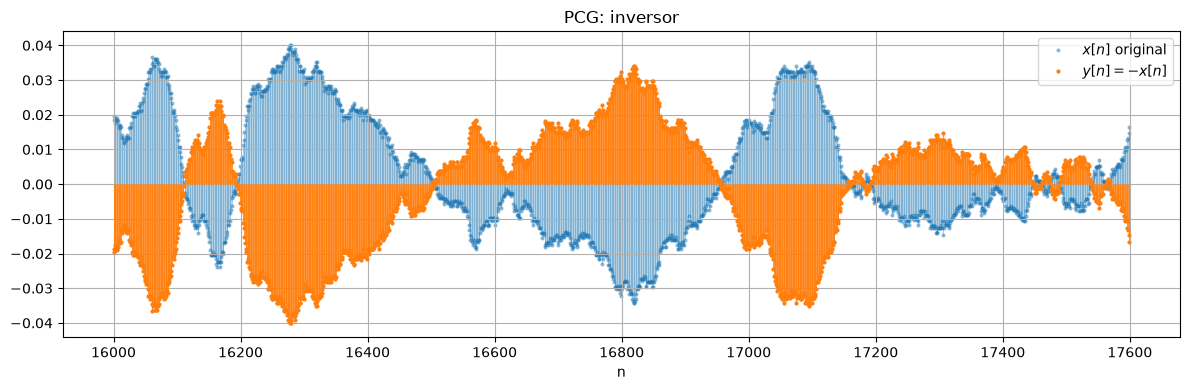

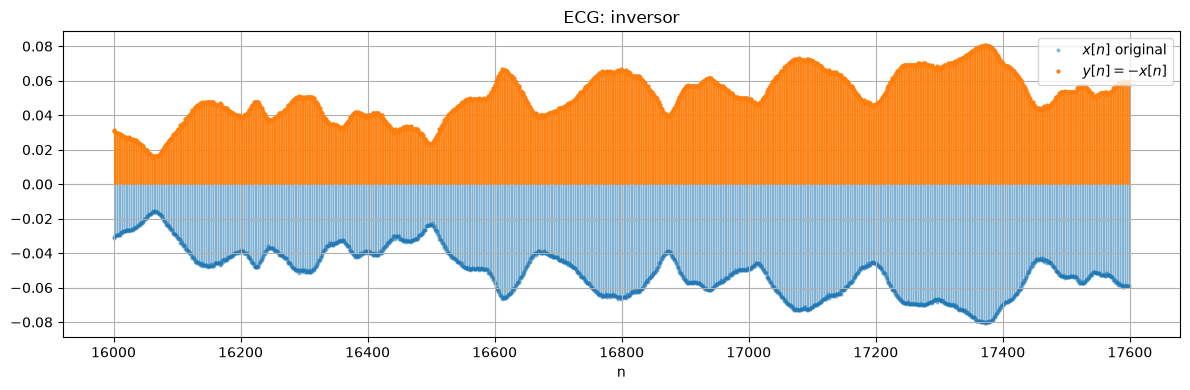

In [62]:
def graficar_inversor(x, fs, titulo, t_ini=2, t_fin=2.2, color_orig='C0', color_inv='C1'):
    k_ini, k_fin = int(t_ini * fs), int(t_fin * fs)
    xv = np.asarray(x[k_ini:k_fin], dtype=float)
    y = inversor(xv)
    n = np.arange(k_ini, k_fin)

    fig, ax = plt.subplots(figsize=(12, 4))

    # original por detrás
    ml, sl, _ = ax.stem(n, xv, basefmt=" ")
    plt.setp(ml, color=color_orig, markersize=2, alpha=0.4, zorder=1)
    plt.setp(sl, color=color_orig, linewidth=0.6, alpha=0.4, zorder=1)
    ml.set_label(r'$x[n]$ original')

    ml, sl, _ = ax.stem(n, y, basefmt=" ")
    plt.setp(ml, color=color_inv, markersize=2, zorder=3)
    plt.setp(sl, color=color_inv, linewidth=0.6, zorder=2)
    ml.set_label(r'$y[n]=-x[n]$')

    ax.set_title(f"{titulo}: inversor")
    ax.set_xlabel('n'); ax.grid(True); ax.legend(loc='upper right')
    plt.tight_layout()
    return fig, ax

graficar_inversor(pcg, fs, 'PCG')
graficar_inversor(ecg, fs, 'ECG')

Vemos que en el tiempo la señal invertida es el espejo de la original respecto del eje horizontal. Luego se observa como en frecuencia no hay cambio en el módulo: la inversión solo cambia la _fase_.

In [60]:
def graficar_inversor_frec(x, fs, titulo, t_ini=2, t_fin=4, fmax=500, umbral_fase=1e-3,
                           color_orig='C0', color_inv='C1'):
    xv = np.asarray(x[int(t_ini * fs):int(t_fin * fs)], dtype=float)
   # xv = xv - xv.mean()                                  # saca el DC
    y = inversor(xv)

    f, X = dtft_muestreada(xv, fs)
    _, Y = dtft_muestreada(y, fs)
    sel = np.abs(f) <= fmax
    f_p, X_p, Y_p = f[sel], X[sel], Y[sel]

    magX, magY = np.abs(X_p), np.abs(Y_p)
    mascara = magX < umbral_fase * magX.max()
    faseX, faseY = np.angle(X_p), np.angle(Y_p)
    faseX[mascara] = 0
    faseY[mascara] = 0

    fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    for ax, a, b, ylabel, nombre in [(axs[0], magX, magY, 'Magnitud [u.a.]', r'|\cdot|'),
                                     (axs[1], faseX, faseY, 'Fase [rad]', r'\angle')]:
        ml, sl, _ = ax.stem(f_p, a, basefmt=" ")
        plt.setp(ml, color=color_orig, markersize=7, alpha=0.4, zorder=1)
        plt.setp(sl, color=color_orig, linewidth=0.8, alpha=0.4, zorder=1)
        ml.set_label(rf'${nombre}\,X(f_k)$ original')

        ml, sl, _ = ax.stem(f_p, b, basefmt=" ")
        plt.setp(ml, color=color_inv, markersize=3, zorder=3)
        plt.setp(sl, color=color_inv, linewidth=0.8, zorder=2)
        ml.set_label(rf'${nombre}\,Y(f_k)$ invertida')

        ax.set_ylabel(ylabel); ax.tick_params(labelbottom=True)
        ax.grid(True); ax.legend(loc='upper right')

    axs[0].set_title(f"{titulo}: módulo")
    axs[1].set_title(f"{titulo}: fase")
    axs[1].set_xlabel('Frecuencia [Hz]')
    axs[0].set_xlim(-fmax, fmax)
    plt.tight_layout()
    return fig, axs


(<Figure size 1200x800 with 2 Axes>,
 array([<Axes: title={'center': 'ECG: módulo'}, ylabel='Magnitud [u.a.]'>,
        <Axes: title={'center': 'ECG: fase'}, xlabel='Frecuencia [Hz]', ylabel='Fase [rad]'>],
       dtype=object))

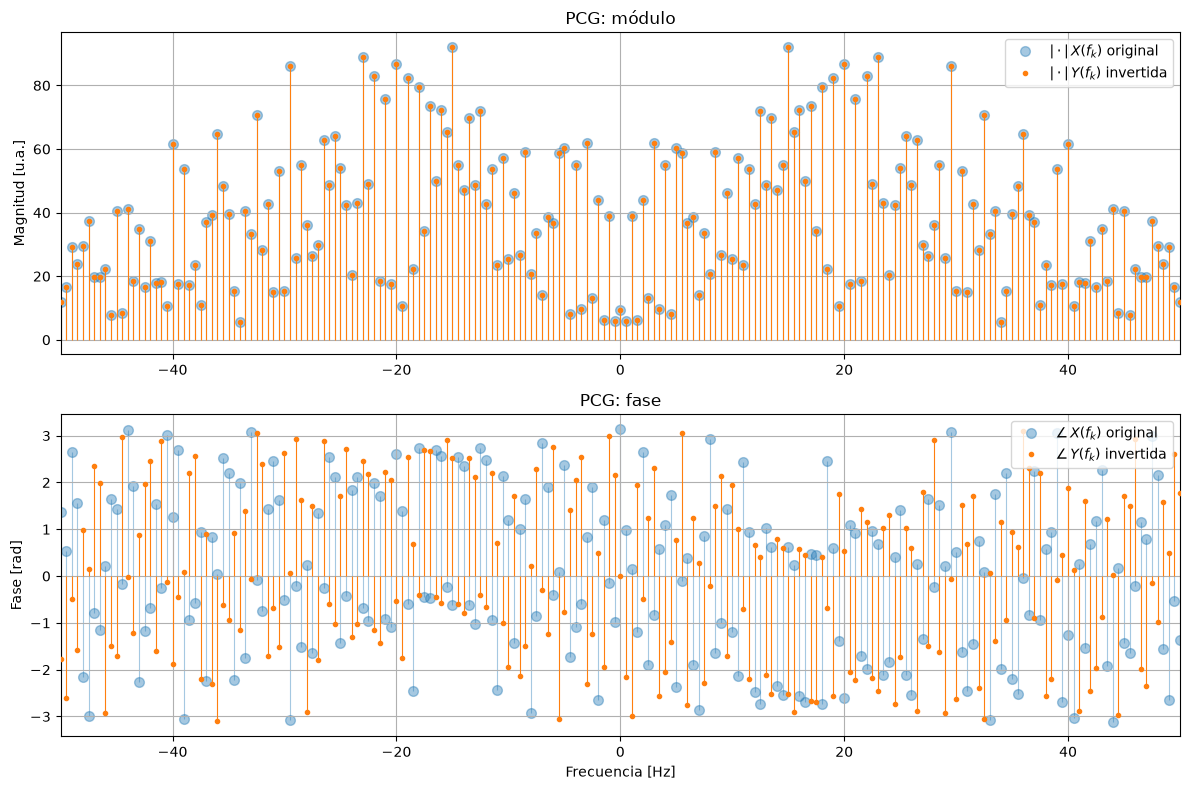

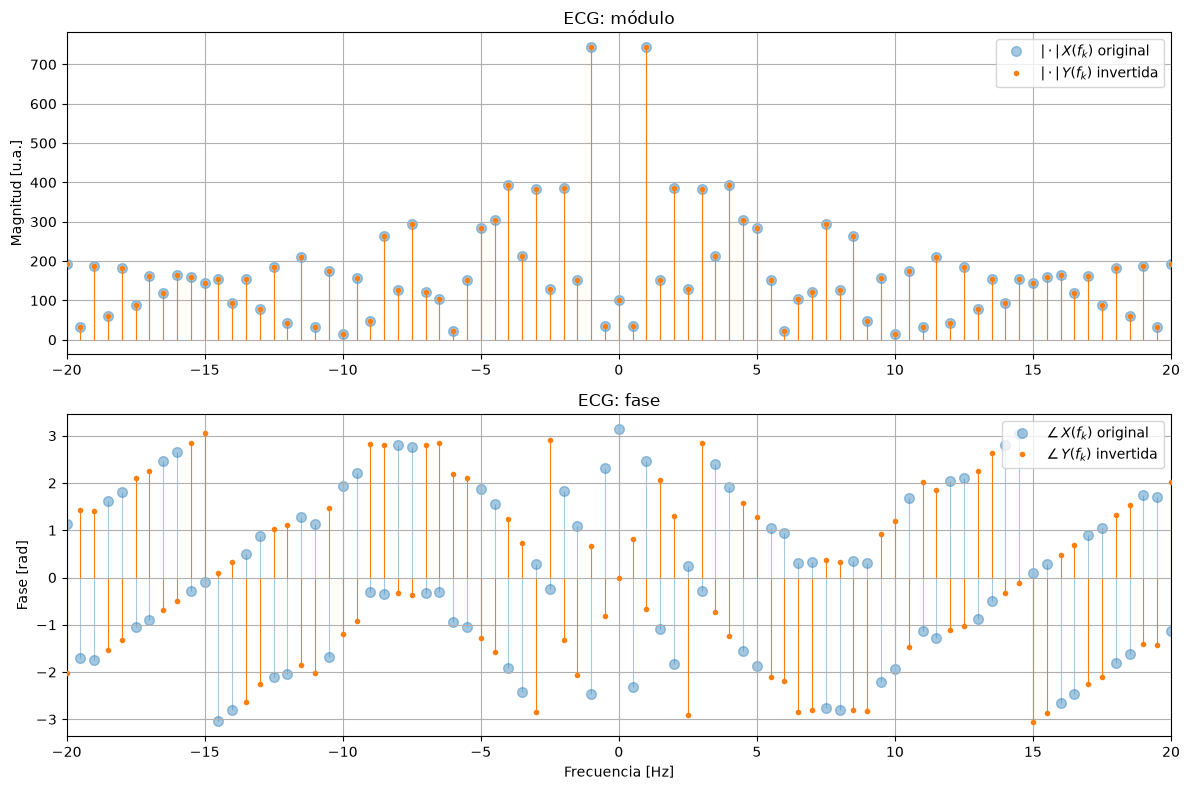

In [61]:

graficar_inversor_frec(pcg, fs, 'PCG', fmax=50)
graficar_inversor_frec(ecg, fs, 'ECG', fmax=20)

#### Sumador

El sumador combina dos o más señales muestra a muestra:

$$y[n] = \sum_{i=1}^{K} a_i\,x_i[n], \qquad a_i \in \mathbb{R}$$

Con $a_i = 1$ es la suma simple $y[n]=x_1[n]+x_2[n]$. Con pesos distintos es una combinación lineal (sumador ponderado), y con $a_2=-1$ es un restador, es decir, un sumador precedido por el inversor de la sección anterior.

Es un sistema sin memoria (cada $y[n]$ depende solo de las entradas en el mismo instante $n$), lineal, invariante en el tiempo y estable: si $|x_i[n]|\le B_i$, entonces $|y[n]| \le \sum_i |a_i| B_i$. Cabe una aclaración sobre la linealidad: el sistema es lineal visto como sistema de $K$ entradas. Si en cambio se lo mira como un sistema de una sola entrada $x$ al que se le suma una señal fija $r[n]$, es decir $y[n]=x[n]+r[n]$, ese sistema _no_ es lineal sino afín: con entrada nula la salida es $r[n] \neq 0$, lo cual viola la homogeneidad. Así es justamente como se modela el ruido aditivo de una medición.

En frecuencia, por linealidad de la transformada:

$$Y(f) = \sum_i a_i X_i(f)$$

De esto se desprenden dos consecuencias. Primero, el sumador no crea frecuencias nuevas: $y$ solo puede tener contenido en las frecuencias donde alguna de las entradas lo tenga (a diferencia, por ejemplo, de multiplicar señales, que convoluciona sus espectros). Segundo, la suma es de números complejos, así que los módulos en general no se suman:

$$\bigl||X_1(f)|-|X_2(f)|\bigr| \;\le\; |Y(f)| \;\le\; |X_1(f)| + |X_2(f)|$$

Donde los espectros no se solapan, $|Y|$ coincide con el de la entrada que ocupa esa banda. Donde se solapan los espectros, el resultado depende de la fase relativa: en fase se refuerzan y en contrafase se cancelan.


A diferencia del inversor, el sumador en general no es invertible: conociendo solo $y$ no se pueden recuperar $x_1$ y $x_2$ por separado, ya que infinitos pares dan la misma suma. Solo puede deshacerse si se conoce al menos una de las entradas.

In [63]:
import numpy as np
import matplotlib.pyplot as plt

def sumador(*senales, pesos=None):
    xs = [np.asarray(x, dtype=float) for x in senales]
    if len(xs) < 2:
        raise ValueError("El sumador necesita al menos dos señales")
    if len({len(x) for x in xs}) != 1:
        raise ValueError("Las señales deben tener la misma cantidad de muestras")
    if pesos is None:
        pesos = np.ones(len(xs))
    if len(pesos) != len(xs):
        raise ValueError("Tiene que haber un peso por señal")

    y = np.zeros_like(xs[0])
    for a, x in zip(pesos, xs):
        y += a * x
    return y

# señales auxiliares para modelar adiciones:
def senoidal(N, fs, f0, amp=1.0, fase=0.0):
    n = np.arange(N)
    return amp * np.cos(2 * np.pi * f0 * n / fs + fase)

def ruido_blanco(N, sigma=1.0, semilla=0):
    return np.random.default_rng(semilla).normal(0, sigma, N)

Para ver el efecto del sumador sobre las señales reales, se lo puede utilizar para modelar las contaminaciones típicas de una medición médica:

- Interferencia de la red eléctrica: senoidal de $50\,\mathrm{Hz}$ que se acopla capacitivamente al paciente y a los cables.
- Ruido de banda ancha: ruido térmico del sensor y del amplificador, o ruido ambiente captado por el micrófono en el caso del PCG. Se modela como ruido blanco gaussiano.

Al ECG se le suma la red, y al PCG el ruido blanco. Se toma la ventana de $2$-$6\,s$: la resolución de la DFT es entonces $1/(4\,s) = 0.25\,\mathrm{Hz}$. Las amplitudes se fijan relativas al máximo de cada ventana para que el efecto sea visible.

In [64]:
t_ini_s, t_fin_s = 2, 6
ecg_v = np.asarray(ecg[int(t_ini_s * fs):int(t_fin_s * fs)], dtype=float)
pcg_v = np.asarray(pcg[int(t_ini_s * fs):int(t_fin_s * fs)], dtype=float)
N_v = len(ecg_v)

A_ecg = np.max(np.abs(ecg_v - ecg_v.mean()))
red_ecg = senoidal(N_v, fs, 50, amp=0.15 * A_ecg)
ecg_red = sumador(ecg_v, red_ecg)

A_pcg = np.max(np.abs(pcg_v - pcg_v.mean()))
blanco_pcg = ruido_blanco(N_v, sigma=0.05 * A_pcg)
pcg_ruido = sumador(pcg_v, blanco_pcg)

(<Figure size 1200x690 with 3 Axes>,
 array([<Axes: title={'center': '$x_1[n]$: PCG'}>,
        <Axes: title={'center': '$x_2[n]$: ruido blanco'}>,
        <Axes: title={'center': 'PCG: salida del sumador'}, xlabel='t (s)'>],
       dtype=object))

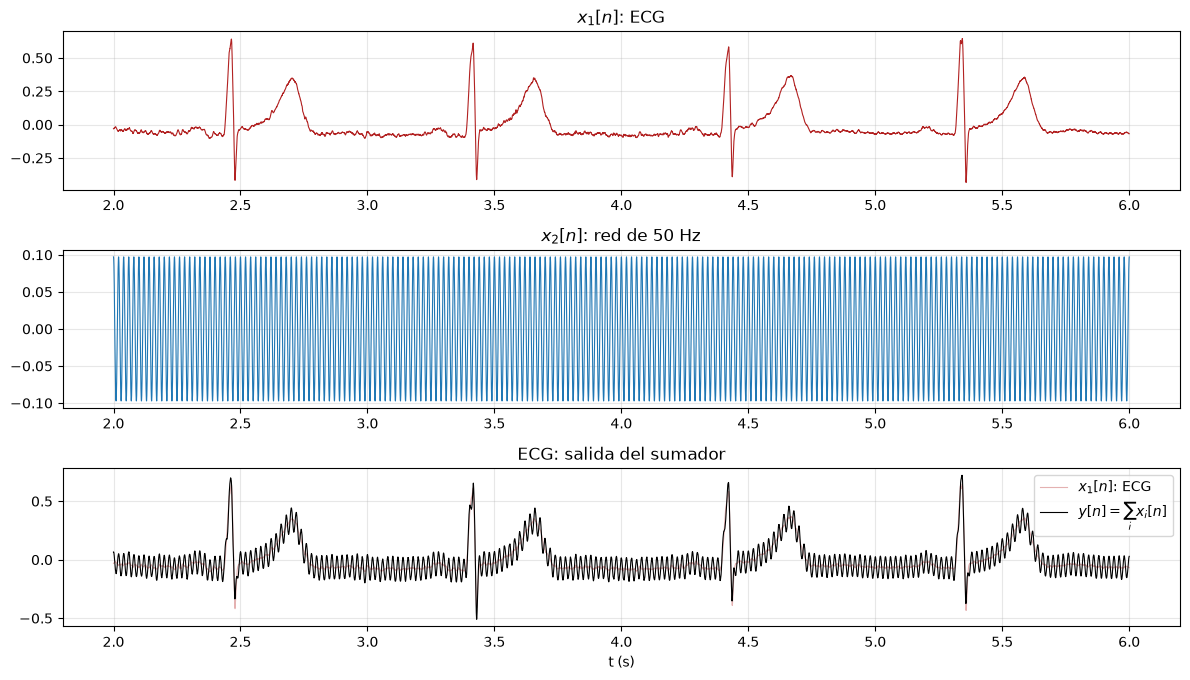

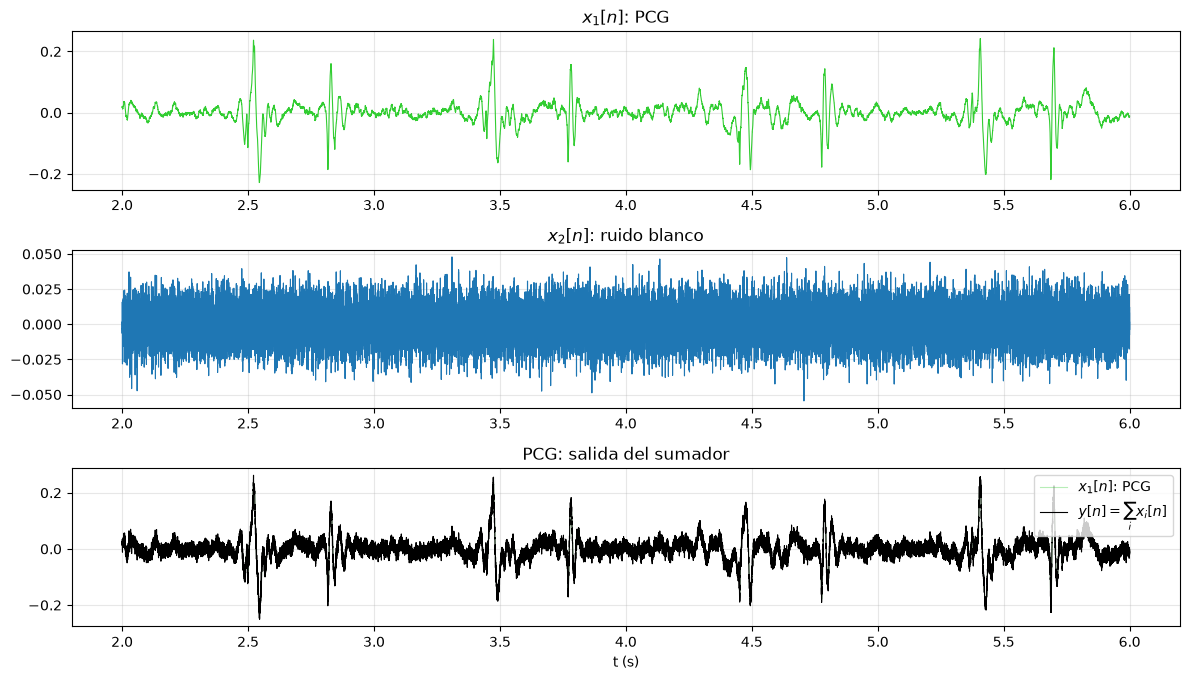

In [71]:
def graficar_sumador(entradas, y, fs, titulo, t_ini=0, zoom=None, colores=None):
    K = len(entradas)
    if colores is None:
        colores = [f'C{i}' for i in range(K)]
    t = t_ini + np.arange(len(y)) / fs

    fig, axs = plt.subplots(K + 1, 1, figsize=(12, 2.3 * (K + 1)), sharex=True)

    for ax, (x, etiqueta), c in zip(axs[:-1], entradas, colores):
        ax.plot(t, x, color=c, linewidth=0.8)
        ax.set_title(etiqueta)
        ax.grid(True, alpha=0.3); ax.tick_params(labelbottom=True)

    axs[-1].plot(t, entradas[0][0], color=colores[0], alpha=0.35, linewidth=0.8,
                 label=entradas[0][1])
    axs[-1].plot(t, y, color='k', linewidth=0.8, label=r'$y[n]=\sum_i x_i[n]$')
    axs[-1].set_title(f'{titulo}: salida del sumador')
    axs[-1].grid(True, alpha=0.3); axs[-1].legend(loc='upper right')
    axs[-1].set_xlabel('t (s)')

    if zoom is not None:
        axs[-1].set_xlim(*zoom)
    plt.tight_layout()
    return fig, axs

graficar_sumador([(ecg_v, r'$x_1[n]$: ECG'),
                  (red_ecg, r'$x_2[n]$: red de 50 Hz')],
                 ecg_red, fs, 'ECG', t_ini=t_ini_s,
                 colores=['firebrick', 'C0', 'C1'])

graficar_sumador([(pcg_v, r'$x_1[n]$: PCG'),
                  (blanco_pcg, r'$x_2[n]$: ruido blanco')],
                 pcg_ruido, fs, 'PCG', t_ini=t_ini_s,
                 colores=['limegreen', 'C0', 'C1'])

Haciendo zoom en $0.3\,s$ se ve con más detalle cómo se superponen las componentes:

(<Figure size 1200x690 with 3 Axes>,
 array([<Axes: title={'center': '$x_1[n]$: PCG'}>,
        <Axes: title={'center': '$x_2[n]$: ruido blanco'}>,
        <Axes: title={'center': 'PCG (zoom): salida del sumador'}, xlabel='t (s)'>],
       dtype=object))

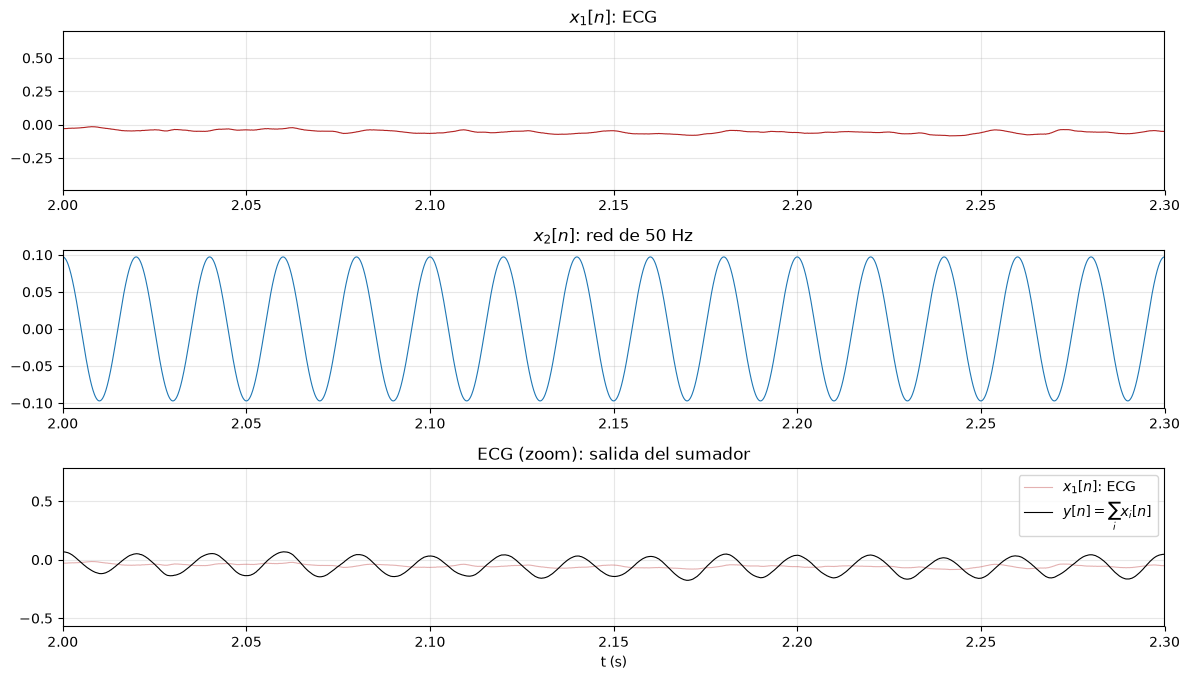

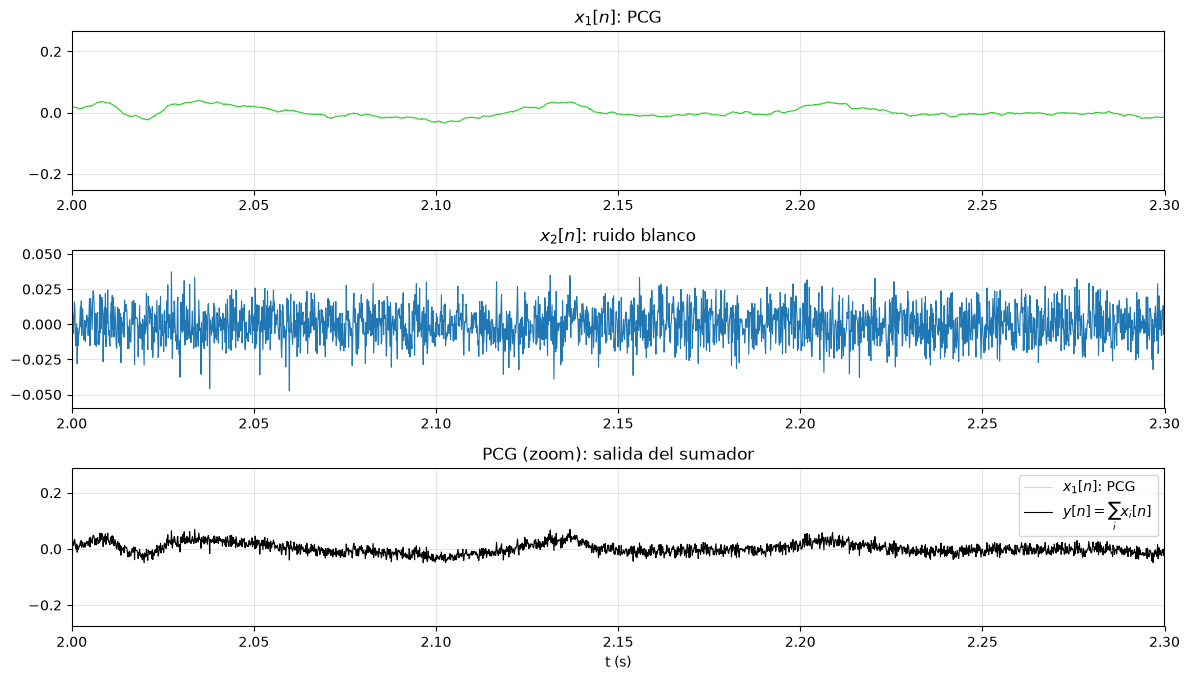

In [72]:
graficar_sumador([(ecg_v, r'$x_1[n]$: ECG'),
                  (red_ecg, r'$x_2[n]$: red de 50 Hz')],
                 ecg_red, fs, 'ECG (zoom)', t_ini=t_ini_s, zoom=(2.0, 2.3),
                 colores=['firebrick', 'C0', 'C1'])

graficar_sumador([(pcg_v, r'$x_1[n]$: PCG'),
                  (blanco_pcg, r'$x_2[n]$: ruido blanco')],
                 pcg_ruido, fs, 'PCG (zoom)', t_ini=t_ini_s, zoom=(2.0, 2.3),
                 colores=['limegreen', 'C0', 'C1'])

En el tiempo, el sumador superpone las entradas muestra a muestra, sin retardos ni deformaciones propias: cada componente sigue estando "entera" dentro de $y[n]$, pero ya no puede verse por separado.

En frecuencia se verifica numéricamente que $Y = \sum_i X_i$ (el error viene por la presición computacional). El espectro de la salida es el del ECG o PCG original con el agregado de las componentes de cada contaminación, y fuera de las bandas que estas ocupan el espectro no cambia en absoluto. No aparece ninguna frecuencia que no estuviera en alguna de las entradas.

- Las senoidales (red y deriva) concentran toda su energía en un único par de bins, $\pm 50\,\mathrm{Hz}$. Por eso pueden eliminarse luego con un filtro muy selectivo, perdiendo muy poca información de la señal.
- El ruido blanco reparte su energía uniformemente en todas las frecuencias, y en dB se ve como un piso plano que se suma al espectro del PCG. En la banda donde el PCG es fuerte ($\lesssim 200\,\mathrm{Hz}$) el piso queda por debajo, pero por encima de $\sim 400\,\mathrm{Hz}$, donde el PCG casi no tiene contenido, el ruido domina. Dentro de la banda útil el ruido no puede separarse con un filtro sin quitar también señal, porque ocupan las mismas frecuencias. Lo único que puede hacer un filtro es descartar las bandas donde no hay señal, como el pasa-bajos en $\sim 400\,\mathrm{Hz}$ propuesto anteriormente.


ECG: max|Y - sum X_i| / max|Y| = 3.03e-16
PCG: max|Y - sum X_i| / max|Y| = 2.12e-16


(<Figure size 1200x800 with 2 Axes>,
 array([<Axes: title={'center': 'PCG: espectros de las entradas'}, ylabel='Magnitud normalizada [dB]'>,
        <Axes: title={'center': 'PCG: espectro de la salida'}, xlabel='Frecuencia [Hz]', ylabel='Magnitud normalizada [dB]'>],
       dtype=object))

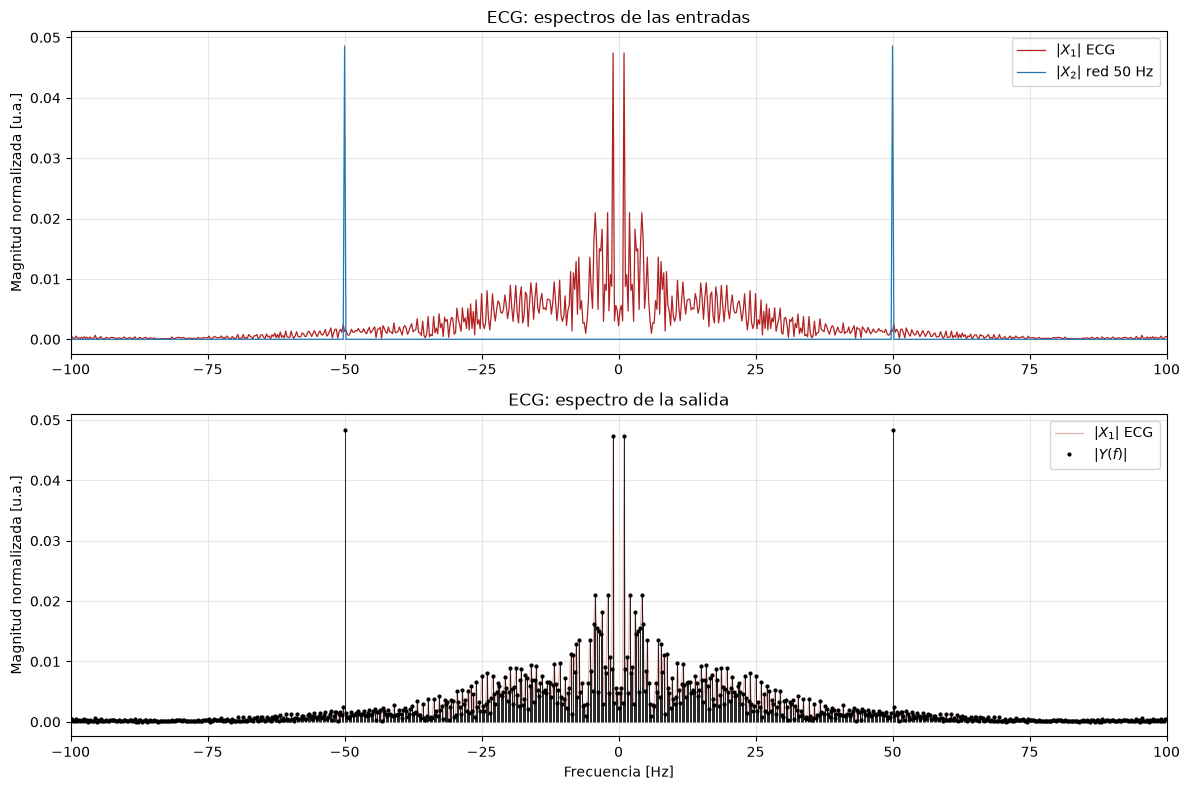

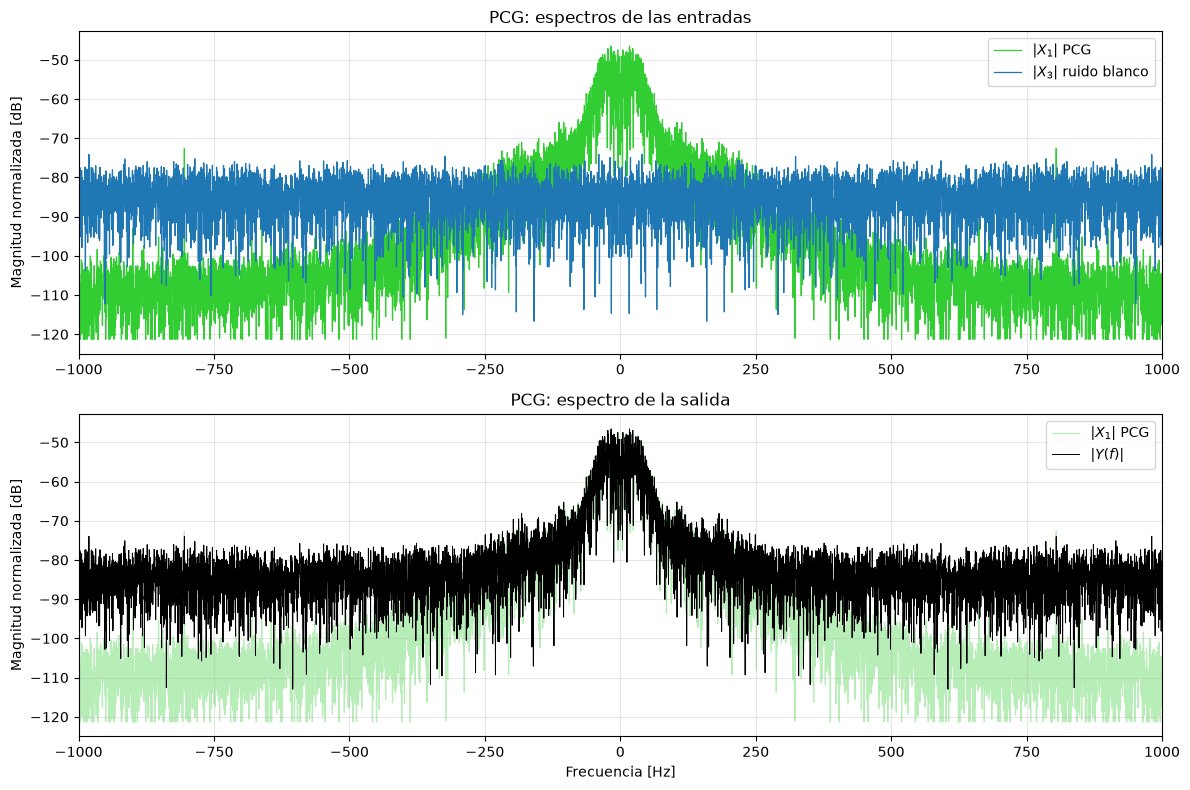

In [70]:
def graficar_sumador_frec(entradas, y, fs, titulo, fmax=100, escala='lin', colores=None):
    K = len(entradas)
    if colores is None:
        colores = [f'C{i}' for i in range(K)]

    # se saca el DC de cada entrada (por linealidad, también se le saca a y)
    xs = [np.asarray(x, dtype=float) for x, _ in entradas]
    yv = np.asarray(y, dtype=float)
    N = len(yv)

    f, Y = dtft_muestreada(yv, fs)
    Xs = [dtft_muestreada(x, fs)[1] for x in xs]

    # Y = sum X_i
    err = np.max(np.abs(Y - np.sum(Xs, axis=0))) / np.max(np.abs(Y))
    print(f"{titulo}: max|Y - sum X_i| / max|Y| = {err:.2e}")

    sel = np.abs(f) <= fmax
    piso = np.percentile(20 * np.log10(np.abs(Y[sel]) / N + 1e-12), 1) - 20
    def mag(Z):
        m = np.abs(Z[sel]) / N
        return np.maximum(20 * np.log10(m + 1e-12), piso) if escala == 'db' else m

    fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True, sharey=True)

    for X, (_, etiqueta), c in zip(Xs, entradas, colores):
        axs[0].plot(f[sel], mag(X), color=c, linewidth=0.9, label=etiqueta)
    axs[0].set_title(f'{titulo}: espectros de las entradas')

    axs[1].plot(f[sel], mag(Xs[0]), color=colores[0], alpha=0.35, linewidth=0.9,
                label=entradas[0][1], zorder=1)
    if escala == 'db':
        axs[1].plot(f[sel], mag(Y), color='k', linewidth=0.7, label=r'$|Y(f)|$', zorder=2)
    else:
        ml, sl, _ = axs[1].stem(f[sel], mag(Y), basefmt=" ")
        plt.setp(ml, color='k', markersize=2, zorder=3)
        plt.setp(sl, color='k', linewidth=0.6, zorder=2)
        ml.set_label(r'$|Y(f)|$')
    axs[1].set_title(f'{titulo}: espectro de la salida')

    ylabel = 'Magnitud normalizada [dB]' if escala == 'db' else 'Magnitud normalizada [u.a.]'
    for ax in axs:
        ax.set_ylabel(ylabel); ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right'); ax.tick_params(labelbottom=True)
    axs[1].set_xlabel('Frecuencia [Hz]')
    axs[0].set_xlim(-fmax, fmax)
    plt.tight_layout()
    return fig, axs

graficar_sumador_frec([(ecg_v, r'$|X_1|$ ECG'),
                       (red_ecg, r'$|X_2|$ red 50 Hz')],
                      ecg_red, fs, 'ECG', fmax=100,
                      colores=['firebrick', 'C0', 'C1'])

# en dB para que se vea el piso del ruido blanco
graficar_sumador_frec([(pcg_v, r'$|X_1|$ PCG'),
                       (blanco_pcg, r'$|X_3|$ ruido blanco')],
                      pcg_ruido, fs, 'PCG', fmax=1000, escala='db',
                      colores=['limegreen', 'C0', 'C1'])

Podemos observar entonces que modelar las distintas "contaminaciones" de las señales capturadas a partir de un sistema sumador es útil dado que, al identificarlas, permiten canclarlas mediante restas (si se conoce la forma exacta de la señal añadida), o mediante filtros si sólo se conoce la frecuencia aproximada.

#### Promediador

El promediador (o media móvil) reemplaza cada muestra por el promedio de las $M$ muestras de una ventana:

$$y[n] = \frac{1}{M}\sum_{k=0}^{M-1} x[n-k]$$

Es un sumador de $M$ copias retardadas de la señal, con peso $1/M$ cada una, es decir, una generalización directa de la suma con copia retardada de la sección anterior. Su respuesta al impulso es un pulso rectangular de largo $M$ y altura $1/M$:

$$h[n] = \frac{1}{M}\left(u[n] - u[n-M]\right)$$

Es un sistema lineal, invariante en el tiempo, causal, con memoria (de $M-1$ muestras) y BIBO-estable, ya que $\sum_n |h[n]| = 1$.

En frecuencia, $Y(f) = H(f)X(f)$, con

$$H(f) = \frac{1}{M}\sum_{k=0}^{M-1} e^{-j2\pi f k/f_s} = \underbrace{\frac{\sin(\pi f M/f_s)}{M\,\sin(\pi f/f_s)}}_{\text{módulo (con signo)}}\; e^{-j\pi f (M-1)/f_s}$$

que se obtiene sumando la serie geométrica. De esta expresión se ve que:

- $H(0) = 1$: el nivel medio (DC) pasa sin cambios, porque el promedio de una constante es la misma constante.
- $|H(f)|$ se anula en $f = k\,f_s/M$, $k = 1, 2, \dots$: una senoidal que completa un número entero de ciclos dentro de la ventana promedia exactamente cero.
- El sistema causal retrasa todas las frecuencias por igual, $(M-1)/2$ muestras. Para comparar la salida con la señal original sin ese retardo, se usa la versión centrada, que promedia la ventana $\left[n - \frac{M-1}{2},\, n + \frac{M-1}{2}\right]$, aunque deja de ser causal.

En este caso, se utilizan dos valores distintos de M: $16$ y $160$.

In [75]:
import numpy as np
import matplotlib.pyplot as plt

M_lista = [16, 160]

def promediador(x, M, centrado=True):
    x = np.asarray(x, dtype=float)
    h = np.ones(M) / M
    y = np.convolve(x, h)  # largo N + M - 1, causal: y[n] = sum_k h[k] x[n-k]
    if centrado:
        ini = (M - 1) // 2  # se compensa el retardo de (M-1)/2 muestras
        return y[ini:ini + len(x)]  # (si M es par queda medio muestra de retardo)
    return y[:len(x)]


def H_promediador(f, M, fs):
    # respuesta en frecuencia del promediador causal (módulo con signo y fase lineal)
    f = np.asarray(f, dtype=float)
    w = np.pi * f / fs
    num = np.sin(M * w)
    den = M * np.sin(w)
    amp = np.where(np.abs(den) < 1e-12, 1.0, num / np.where(den == 0, 1, den))
    return amp * np.exp(-1j * w * (M - 1))  #### Derivador


Se puede aplicar al ECG contaminado con la senoidal de la sección del sumador (red de $50\,\mathrm{Hz}$):

$$x_r[n] = x[n] + \underbrace{r_{50}[n] }$$

Por linealidad, la salida es $y = h*x + h*r_{50} $, de modo que cada término puede analizarse por separado: la senoidal sale escalada por $|H|$ en su frecuencia, y el ECG sale filtrado por $H$.

(<Figure size 1200x920 with 4 Axes>,
 array([<Axes: title={'center': 'ECG: original'}>,
        <Axes: title={'center': 'ECG: contaminada'}>,
        <Axes: title={'center': 'ECG: promediada con $M=16$ (2 ms)'}>,
        <Axes: title={'center': 'ECG: promediada con $M=160$ (20 ms)'}, xlabel='t (s)'>],
       dtype=object))

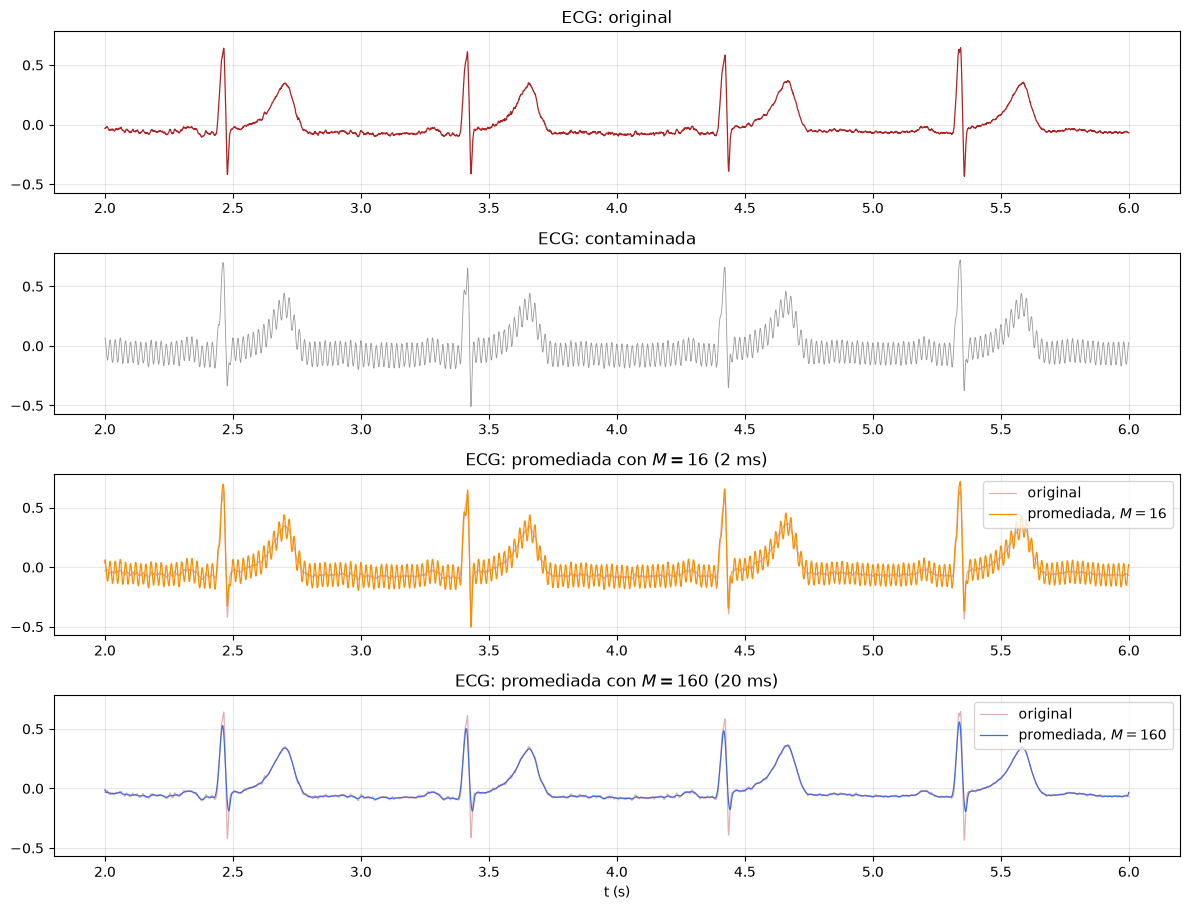

In [83]:


y_ecg = {M: promediador(ecg_red, M) for M in M_lista}

def graficar_promediador(x, x_r, ys, fs, titulo, t_ini=0, zoom=None,
                         color_orig='C0', color_r='0.6'):
    t = t_ini + np.arange(len(x)) / fs
    fig, axs = plt.subplots(2 + len(ys), 1, figsize=(12, 2.3 * (2 + len(ys))),
                            sharex=True, sharey=True)

    axs[0].plot(t, x, color=color_orig, linewidth=0.9)
    axs[0].set_title(f'{titulo}: original')
    axs[1].plot(t, x_r, color=color_r, linewidth=0.6)
    axs[1].set_title(f'{titulo}: contaminada')

    for ax, (M, y), c in zip(axs[2:], ys.items(), ['darkorange', 'royalblue', 'C4']):
        ax.plot(t, x, color=color_orig, alpha=0.35, linewidth=0.9, label='original')
        ax.plot(t, y, color=c, linewidth=0.9, label=rf'promediada, $M={M}$')
        ax.set_title(rf'{titulo}: promediada con $M={M}$ ({1000 * M / fs:.0f} ms)')
        ax.legend(loc='upper right')

    for ax in axs:
        ax.grid(True, alpha=0.3); ax.tick_params(labelbottom=True)
    axs[-1].set_xlabel('t (s)')
    if zoom is not None:
        axs[-1].set_xlim(*zoom)
    plt.tight_layout()
    return fig, axs

graficar_promediador(ecg_v, ecg_red, y_ecg, fs, 'ECG', t_ini=t_ini_s,
                     color_orig='firebrick')

Podemos ver como con $M=16$ no se elimina la contaminación de manera sustancial, pero con $M=160$ se eliminan, aunque a costa de sacrificar parte de la información de la señal (por ejemplo los picos R no se recuperan completos sino que tienen menor amplitud.

(<Figure size 1200x800 with 4 Axes>,
 array([<Axes: title={'center': 'ECG: espectro, $M=16$'}, ylabel='Magnitud normalizada [u.a.]'>,
        <Axes: title={'center': 'ECG: espectro, $M=160$'}, xlabel='Frecuencia [Hz]', ylabel='Magnitud normalizada [u.a.]'>],
       dtype=object))

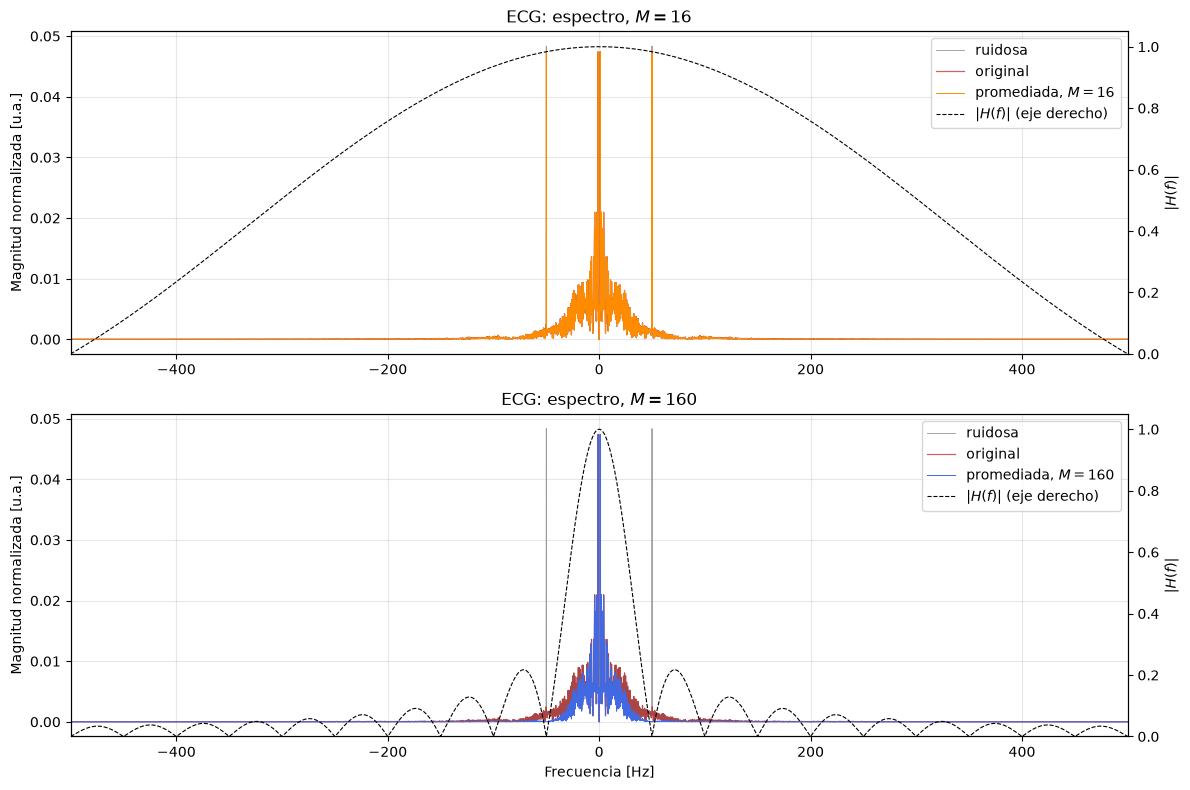

In [91]:
def graficar_promediador_frec(x, x_r, ys, fs, titulo, fmax=500,
                              color_orig='C0', color_r='0.6'):
    N = len(x)
    f, X = dtft_muestreada(x - np.mean(x), fs)
    _, Xr = dtft_muestreada(x_r - np.mean(x_r), fs)
    sel = np.abs(f) <= fmax
    mod = lambda Z: np.abs(Z[sel]) / N

    fig, axs = plt.subplots(len(ys), 1, figsize=(12, 4 * len(ys)), sharex=True, sharey=True)
    axs = np.atleast_1d(axs)
    for ax, (M, y), c in zip(axs, ys.items(), ['darkorange', 'royalblue', 'C4']):
        _, Y = dtft_muestreada(y - np.mean(y), fs)
        ax.plot(f[sel], mod(Xr), color=color_r, linewidth=0.6, label='ruidosa')
        ax.plot(f[sel], mod(X), color=color_orig, linewidth=0.9, alpha=0.7, label='original')
        ax.plot(f[sel], mod(Y), color=c, linewidth=0.7, label=rf'promediada, $M={M}$')
        ax.set_title(rf'{titulo}: espectro, $M={M}$')
        ax.set_ylabel('Magnitud normalizada [u.a.]')
        ax.grid(True, alpha=0.3); ax.tick_params(labelbottom=True)

        # |H| en un eje secundario, para ver la forma del filtro
        ax_h = ax.twinx()
        ax_h.plot(f[sel], np.abs(H_promediador(f[sel], M, fs)),
                  color='k', linestyle='--', linewidth=0.8, label=r'$|H(f)|$ (eje derecho)')
        ax_h.set_ylim(0, 1.05)
        ax_h.set_ylabel(r'$|H(f)|$')

        # leyenda única con las curvas de ambos ejes
        h1, l1 = ax.get_legend_handles_labels()
        h2, l2 = ax_h.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, loc='upper right')

    axs[-1].set_xlabel('Frecuencia [Hz]')
    axs[0].set_xlim(-fmax, fmax)
    plt.tight_layout()
    return fig, axs

graficar_promediador_frec(ecg_v, ecg_red, y_ecg, fs, 'ECG', fmax=500,
                          color_orig='firebrick')

Se aplica también el promediador al PCG contaminado de la sección del sumador (PCG + ruido blanco), comparando con el PCG original. Vemos que en este caso $M=16$ es suficiente para deshacerse del ruido, y el promediado con $M=160$ deforma la señal.

(<Figure size 1200x920 with 4 Axes>,
 array([<Axes: title={'center': 'PCG: original'}>,
        <Axes: title={'center': 'PCG: contaminada'}>,
        <Axes: title={'center': 'PCG: promediada con $M=16$ (2 ms)'}>,
        <Axes: title={'center': 'PCG: promediada con $M=160$ (20 ms)'}, xlabel='t (s)'>],
       dtype=object))

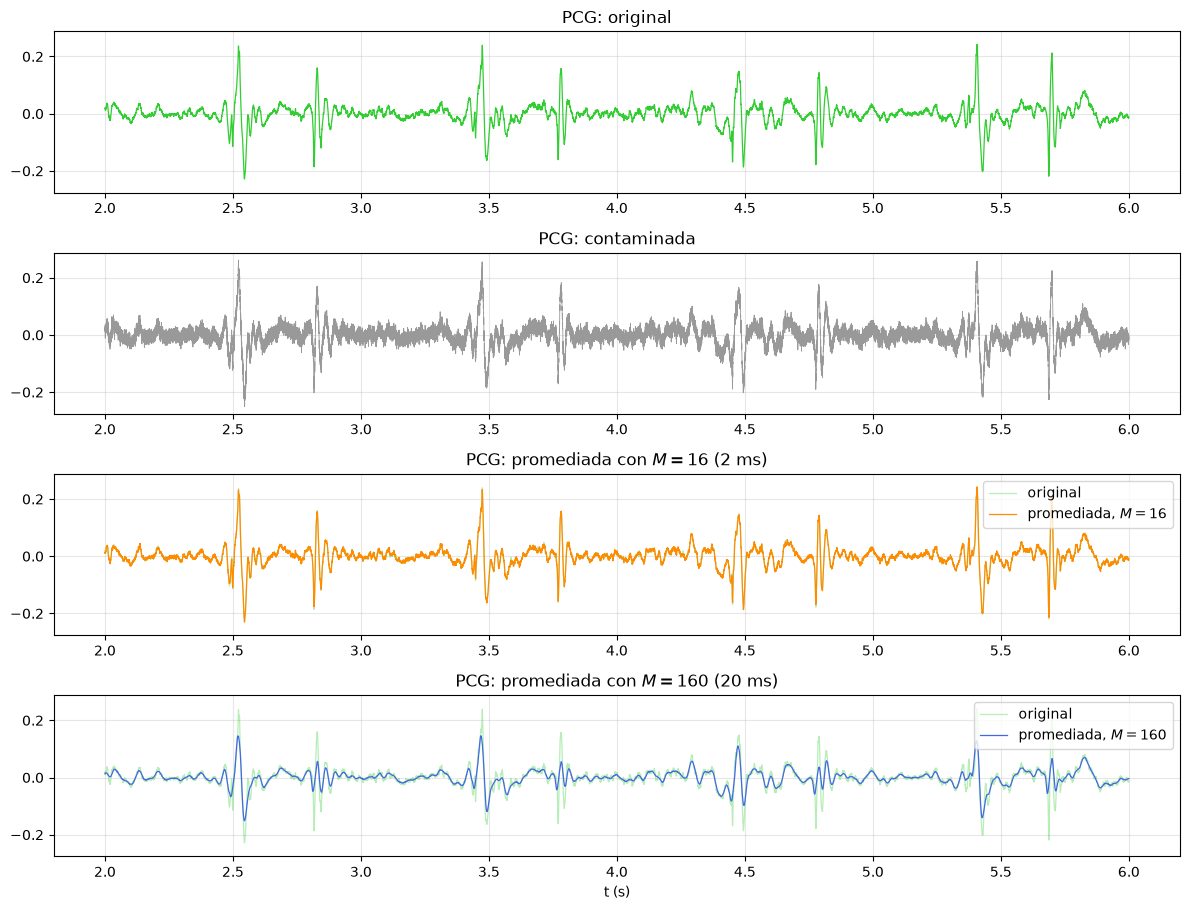

In [87]:
y_pcg = {M: promediador(pcg_ruido, M) for M in M_lista}

graficar_promediador(pcg_v, pcg_ruido, y_pcg, fs, 'PCG', t_ini=t_ini_s,
                     color_orig='limegreen')

(<Figure size 1200x800 with 4 Axes>,
 array([<Axes: title={'center': 'PCG: espectro, $M=16$'}, ylabel='Magnitud normalizada [u.a.]'>,
        <Axes: title={'center': 'PCG: espectro, $M=160$'}, xlabel='Frecuencia [Hz]', ylabel='Magnitud normalizada [u.a.]'>],
       dtype=object))

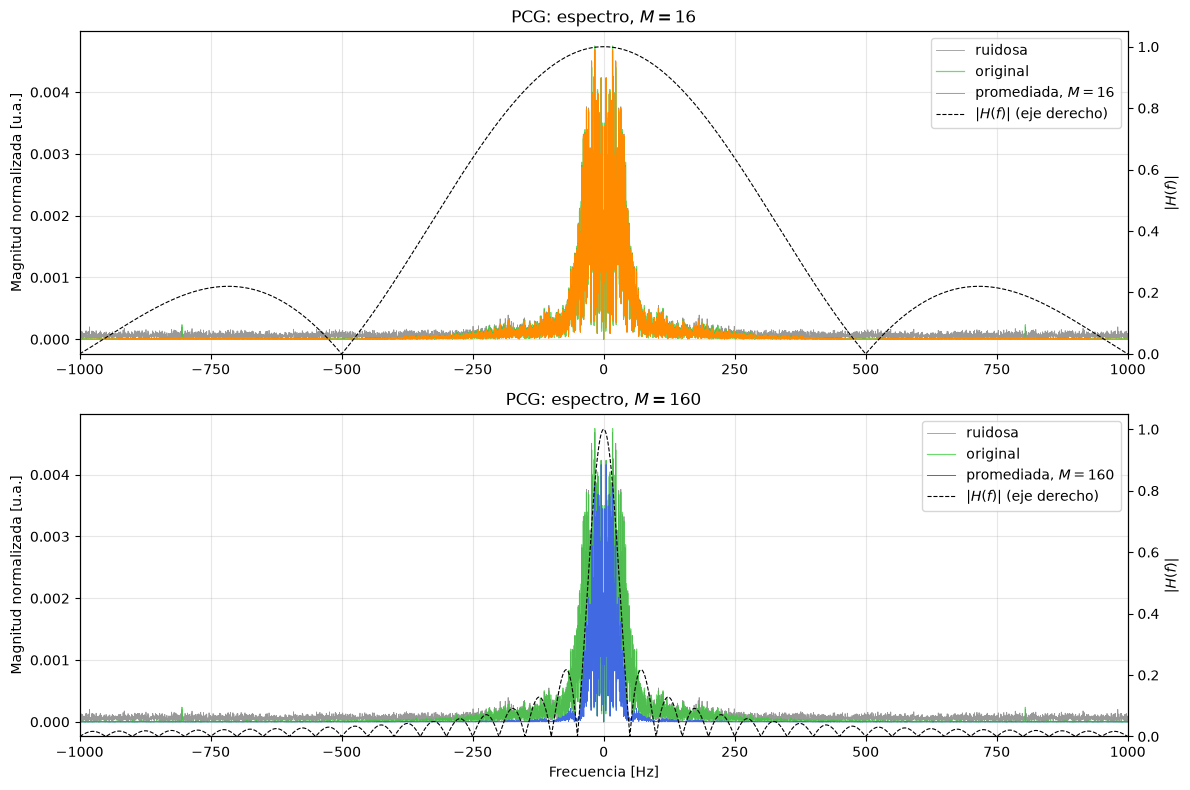

In [93]:
graficar_promediador_frec(pcg_v, pcg_ruido, y_pcg, fs, 'PCG', fmax=1000,
                          color_orig='limegreen')

En conclusión, el promediador funciona como un filtro pasa-bajos: promediar muestras vecinas deja pasar las componentes que varían poco dentro de la ventana y atenúa las que oscilan dentro de ella, hasta anularlas cuando la ventana contiene un número entero de ciclos. El largo de la ventana $M$ determina la frecuencia de corte.

Esto plantea un compromiso al elegir $M$. Una ventana más larga reduce más el ruido, pero baja también la frecuencia de corte y empieza a atenuar y deformar la propia señal, como ocurrió con el ECG y PCG para $M = 160$. Por eso $M$ debe elegirse a partir de la banda de la señal de interés y no de cuánto ruido se quiere quitar.

Además, el promediador actúa por frecuencia y no puede distinguir señal de ruido dentro de una misma banda. Solo elimina las contaminaciones que están por encima de la banda de la señal.

#### Derivador

El derivador aproxima la derivada temporal de la señal a partir de sus muestras ([fuente](https://wirelesspi.com/design-of-a-discrete-time-differentiator/)). La forma más simple es la diferencia hacia atrás:

$$y[n] = \frac{x[n] - x[n-1]}{T} = f_s\bigl(x[n] - x[n-1]\bigr)$$

que es la pendiente de la recta entre dos muestras consecutivas. Se divide por $T = 1/f_s$ para que $y$ sea comparable con $\frac{dx_c}{dt}$.

Puede observarse que es un sumador de la señal con una copia retardada e invertida de sí misma, es decir, se construye con los dos sistemas anteriormente analizados. Su respuesta al impulso es:
$$h[n] = f_s\bigl(\delta[n] - \delta[n-1]\bigr)$$.

Es un sistema lineal, invariante en el tiempo, causal y con memoria de una muestra.

En frecuencia, la derivada continua corresponde a multiplicar por $j2\pi f$, de modo que una senoidal de amplitud $A$ y frecuencia $f$ sale con amplitud $2\pi f A$ y adelantada $90^\circ$. Para la diferencia hacia atrás:

$$H(f) = f_s\left(1 - e^{-j2\pi f/f_s}\right) = \underbrace{2f_s\sin\!\left(\frac{\pi f}{f_s}\right)}_{|H(f)|}\; e^{\,j\left(\frac{\pi}{2} - \frac{\pi f}{f_s}\right)}$$

Se ve entonces que:

- $H(0) = 0$: la componente continua se elimina por completo, porque la derivada de una constante es cero.
- $|H|$ crece con la frecuencia, aproximadamente en forma lineal: es un pasa-altos. Cuanto más rápido varía una componente, más se amplifica.
- El máximo está en $f_s/2$, con $|H| = 2f_s$, que es donde está el ruido de más alta frecuencia que puede representarse.


In [99]:
import numpy as np
import matplotlib.pyplot as plt

def retardar(x, D=1):
    x = np.asarray(x, dtype=float)
    return np.concatenate([np.full(D, x[0]), x[:-D]])

# se construye a partir del inversor y el sumador hechos anteriormente
def derivador(x, fs):
    return fs * sumador(x, inversor(retardar(x)))

def H_derivador(f, fs):
    w = 2 * np.pi * np.asarray(f, dtype=float) / fs
    return fs * (1 - np.exp(-1j * w))


(<Figure size 1200x950 with 4 Axes>,
 array([<Axes: title={'center': 'ECG: original'}>,
        <Axes: title={'center': 'ECG: contaminada'}>,
        <Axes: title={'center': 'ECG: derivada de la original'}, ylabel='$[x]/\\mathrm{s}$'>,
        <Axes: title={'center': 'ECG: derivada de la contaminada'}, xlabel='t (s)', ylabel='$[x]/\\mathrm{s}$'>],
       dtype=object))

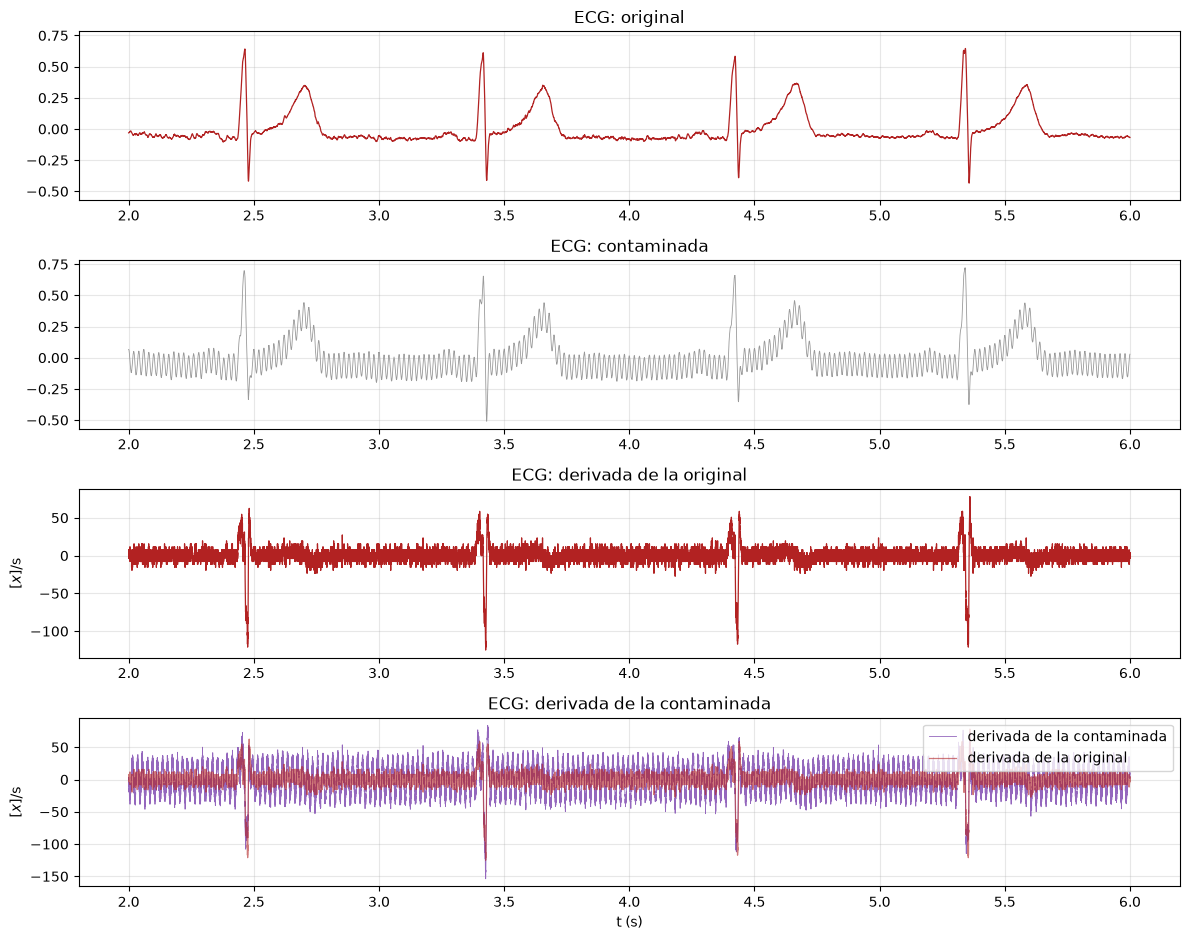

In [103]:
def graficar_derivador(x, x_r, fs, titulo, t_ini=0, zoom=None,
                       color_orig='C0', color_r='0.6', color_d='C4'):
    t = t_ini + np.arange(len(x)) / fs
    dx = derivador(x, fs)
    dx_r = derivador(x_r, fs)

    fig, axs = plt.subplots(4, 1, figsize=(12, 9.5), sharex=True)
    axs[0].plot(t, x, color=color_orig, linewidth=0.9)
    axs[0].set_title(f'{titulo}: original')
    axs[1].plot(t, x_r, color=color_r, linewidth=0.6)
    axs[1].set_title(f'{titulo}: contaminada')
    axs[2].plot(t, dx, color=color_orig, linewidth=0.9)
    axs[2].set_title(rf'{titulo}: derivada de la original')
    axs[3].plot(t, dx_r, color=color_d, linewidth=0.6, label='derivada de la contaminada')
    axs[3].plot(t, dx, color=color_orig, linewidth=0.9, alpha=0.6, label='derivada de la original')
    axs[3].set_title(rf'{titulo}: derivada de la contaminada')
    axs[3].legend(loc='upper right')

    axs[0].sharey(axs[1])
    axs[2].set_ylabel(r'$[x]/\mathrm{s}$'); axs[3].set_ylabel(r'$[x]/\mathrm{s}$')
    for ax in axs:
        ax.grid(True, alpha=0.3); ax.tick_params(labelbottom=True)
    axs[-1].set_xlabel('t (s)')
    if zoom is not None:
        axs[-1].set_xlim(*zoom)
        # se ajusta la escala vertical de las derivadas al tramo visible
        i = (t >= zoom[0]) & (t <= zoom[1])
        lim = 1.1 * np.max(np.abs(dx[i]))
        axs[2].set_ylim(-lim, lim)
    plt.tight_layout()
    return fig, axs

graficar_derivador(ecg_v, ecg_red, fs, 'ECG', t_ini=t_ini_s, color_orig='firebrick')


(<Figure size 1200x800 with 3 Axes>,
 array([<Axes: title={'center': 'ECG: espectro de la entrada'}, ylabel='Magnitud normalizada [u.a.]'>,
        <Axes: title={'center': 'ECG: espectro de la salida'}, xlabel='Frecuencia [Hz]', ylabel='Magnitud normalizada [u.a./s]'>],
       dtype=object))

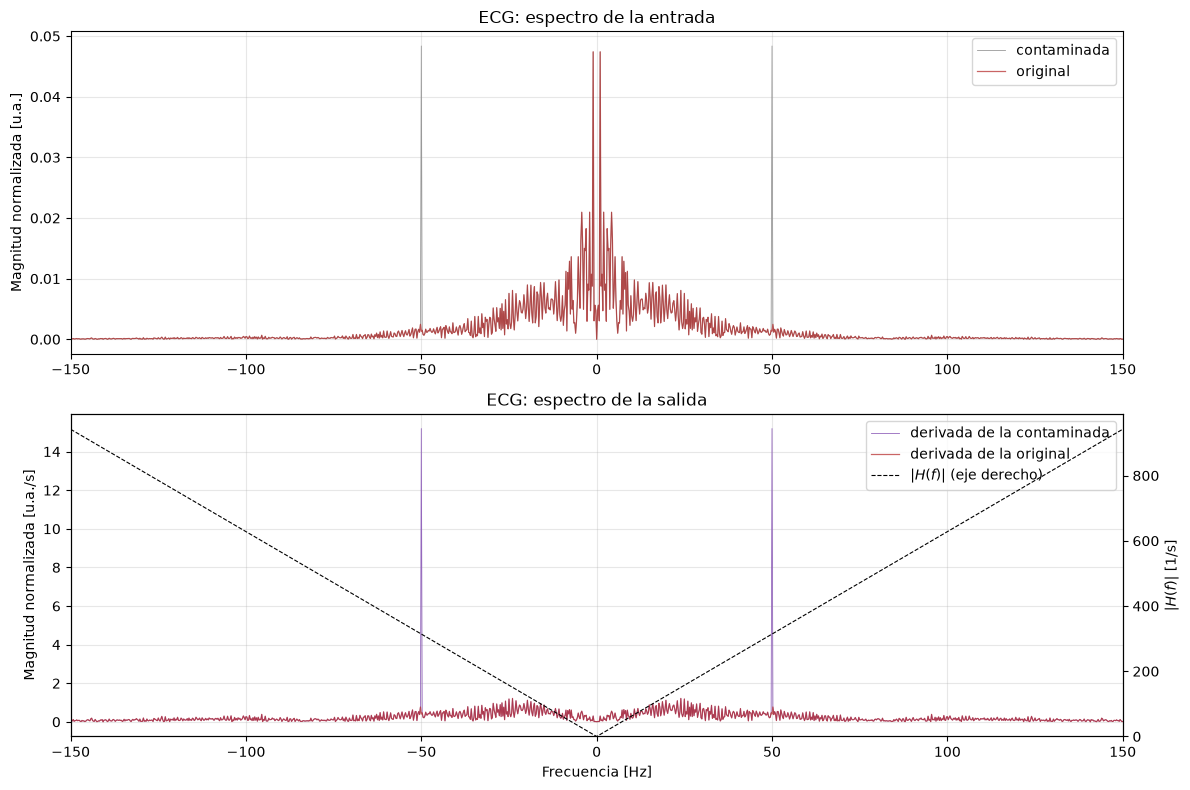

In [106]:
def graficar_derivador_frec(x, x_r, fs, titulo, fmax=500,
                            color_orig='C0', color_r='0.6', color_d='C4'):
    N = len(x)
    f, X = dtft_muestreada(x - np.mean(x), fs)
    _, Xr = dtft_muestreada(x_r - np.mean(x_r), fs)
    _, DX = dtft_muestreada(derivador(x, fs), fs)
    _, DXr = dtft_muestreada(derivador(x_r, fs), fs)
    sel = np.abs(f) <= fmax
    mod = lambda Z: np.abs(Z[sel]) / N

    fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    axs[0].plot(f[sel], mod(Xr), color=color_r, linewidth=0.6, label='contaminada')
    axs[0].plot(f[sel], mod(X), color=color_orig, linewidth=0.9, alpha=0.7, label='original')
    axs[0].set_title(f'{titulo}: espectro de la entrada')
    axs[0].set_ylabel('Magnitud normalizada [u.a.]')
    axs[0].legend(loc='upper right')

    axs[1].plot(f[sel], mod(DXr), color=color_d, linewidth=0.6, label='derivada de la contaminada')
    axs[1].plot(f[sel], mod(DX), color=color_orig, linewidth=0.9, alpha=0.7,
                label='derivada de la original')
    axs[1].set_title(f'{titulo}: espectro de la salida')
    axs[1].set_ylabel(r'Magnitud normalizada [u.a./s]')

    # |H| en un eje secundario, para ver la forma del filtro
    ax_h = axs[1].twinx()
    ax_h.plot(f[sel], np.abs(H_derivador(f[sel], fs)), color='k', linestyle='--',
              linewidth=0.8, label=r'$|H(f)|$ (eje derecho)')
    ax_h.set_ylim(0, None)
    ax_h.set_ylabel(r'$|H(f)|$ [1/s]')
    h1, l1 = axs[1].get_legend_handles_labels()
    h2, l2 = ax_h.get_legend_handles_labels()
    axs[1].legend(h1 + h2, l1 + l2, loc='upper right')

    for ax in axs:
        ax.grid(True, alpha=0.3); ax.tick_params(labelbottom=True)
    axs[1].set_xlabel('Frecuencia [Hz]')
    axs[0].set_xlim(-fmax, fmax)
    plt.tight_layout()
    return fig, axs

graficar_derivador_frec(ecg_v, ecg_red, fs, 'ECG', fmax=150, color_orig='firebrick')

Sobre el ECG limpio, la derivada **resalta** las partes de variación rápida: el QRS produce un pico positivo en la subida de la R, uno negativo en la bajada y un cruce por cero justo en el pico de la R, mientras que las ondas P y T, mucho más lentas, dan derivadas pequeñas. El derivador "realza" el QRS frente al resto del latido, lo cual es útil para detectarlo y luego analizarlo.

Dada la respuesta en frecuencia del filtro, vemos que tiene un comportamiento _pasa-alto_. Sin embargo, observamos que para la contaminación proveniente de la red ($50Hz$), el contenido de esta señal adquiere mucho mayor peso relativo, y termina por tapar gran parte de la derivada de la señal original. Esto indica que, para obtener un buen resultado, este tipo de contaminación debiera descartarse antes de realiizar este procesamiento.

Sin embargo, si comparamos el resultado obtenido para la ECG (contaminada) con el PCG contaminado, vemos que este filtro sí es exitoso en eliminar las componentes frecuenciales correspondientes a la contaminación de ruido gaussiano, dado que el contenido del mismo se encuentra a más altas frecuencias.

(<Figure size 1200x800 with 3 Axes>,
 array([<Axes: title={'center': 'PCG: espectro de la entrada'}, ylabel='Magnitud normalizada [u.a.]'>,
        <Axes: title={'center': 'PCG: espectro de la salida'}, xlabel='Frecuencia [Hz]', ylabel='Magnitud normalizada [u.a./s]'>],
       dtype=object))

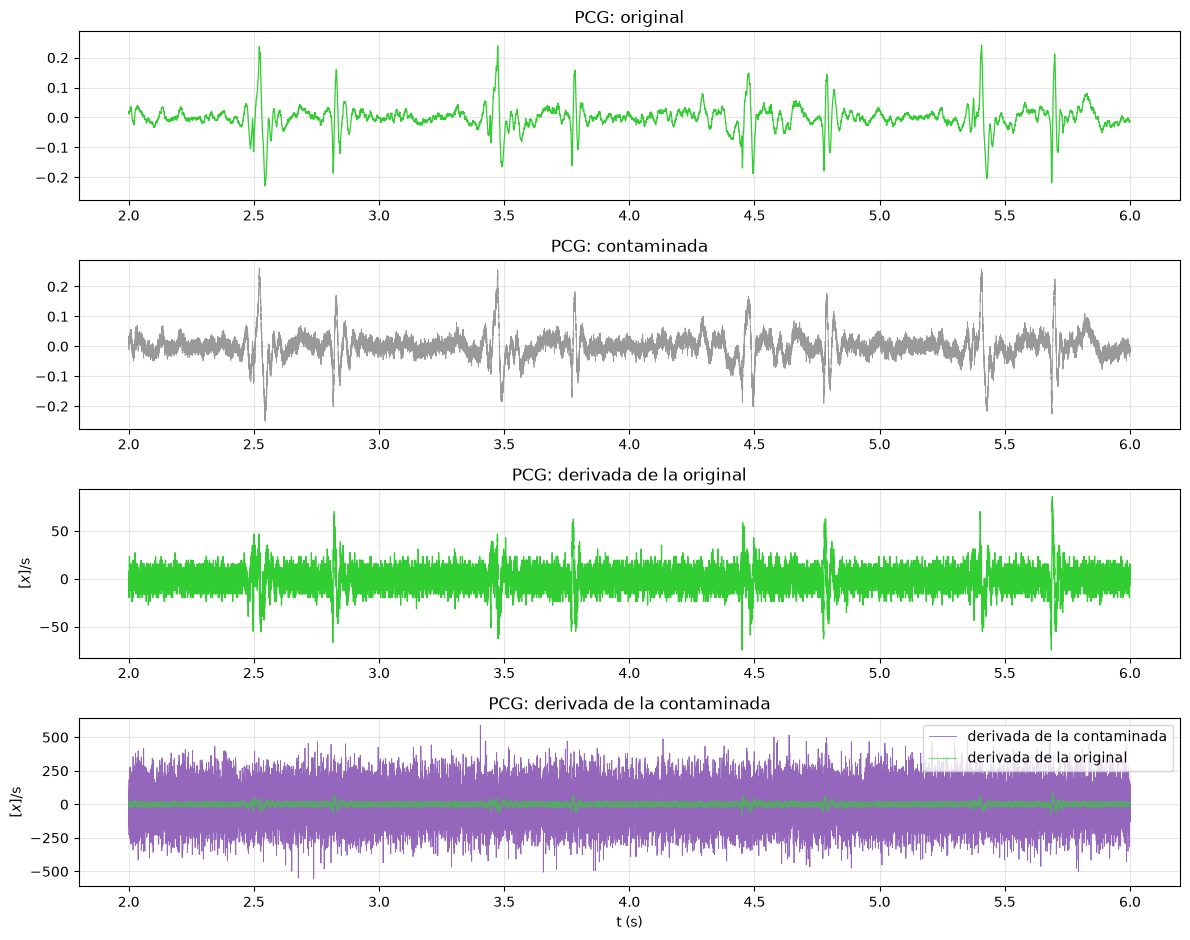

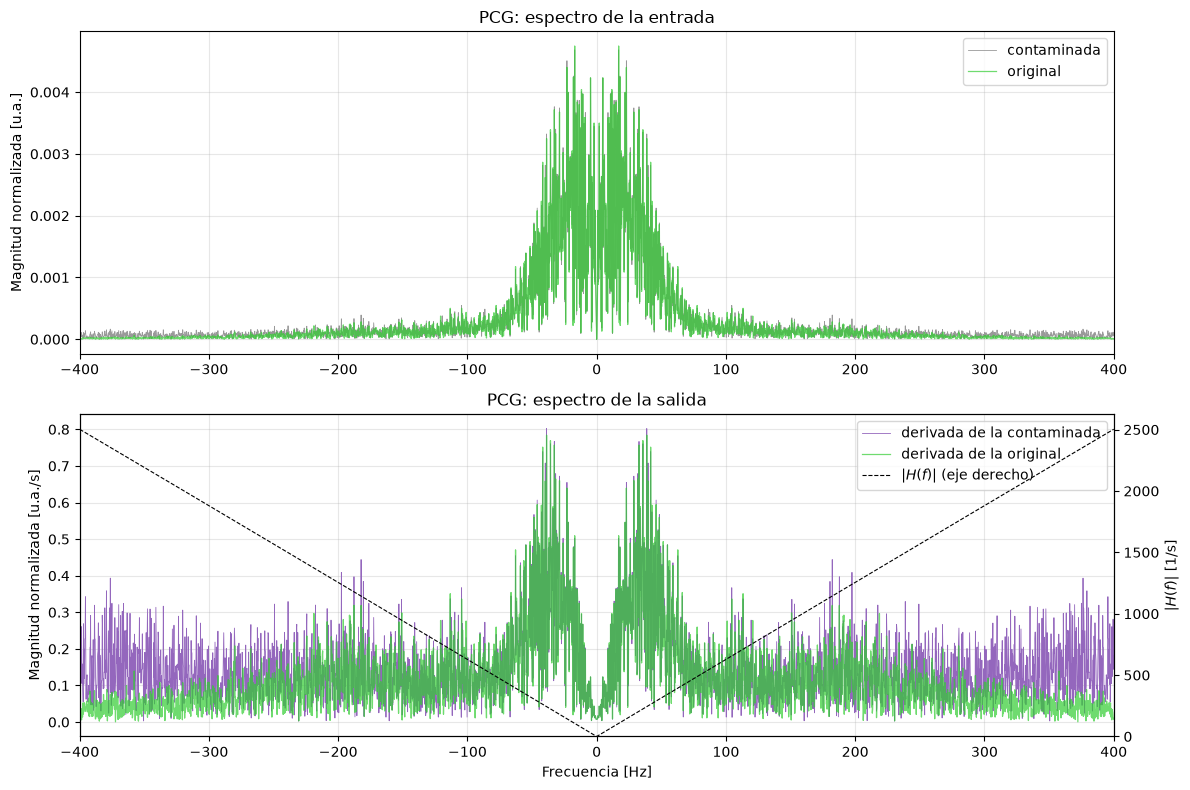

In [108]:
graficar_derivador(pcg_v, pcg_ruido, fs, 'PCG', t_ini=t_ini_s, color_orig='limegreen')

graficar_derivador_frec(pcg_v, pcg_ruido, fs, 'PCG', fmax=400, color_orig='limegreen')


#### Modelado de sistema a partir de circuito RLC


## Referencias
- https://advancedmedicalcertification.com/pqrst-wave-explained-for-beginners
- https://agustinsolano.github.io/SyS_scriptsbook/md_scripts/Computo_TFourier_FFT_senial_real.html
- https://pmc.ncbi.nlm.nih.gov/articles/PMC12953169/
- https://www.robots.ox.ac.uk/~gari/teaching/cdt/A3/readings/ECG/Pan+Tompkins.pdf
- https://zeus.azc.uam.mx/caviles/files/pdscap3.pdf
- https://wirelesspi.com/design-of-a-discrete-time-differentiator/